SNR= 0 dB | SVR+heur=8.1239e-02 | LS=8.9590e-02
SNR= 5 dB | SVR+heur=3.3086e-02 | LS=6.6015e-02
SNR=10 dB | SVR+heur=1.0407e-02 | LS=6.6545e-02
SNR=15 dB | SVR+heur=4.7992e-03 | LS=6.7463e-02
SNR=20 dB | SVR+heur=1.1206e-03 | LS=6.7429e-02
SNR=25 dB | SVR+heur=2.0568e-04 | LS=6.7698e-02
SNR=30 dB | SVR+heur=3.9108e-05 | LS=6.7633e-02


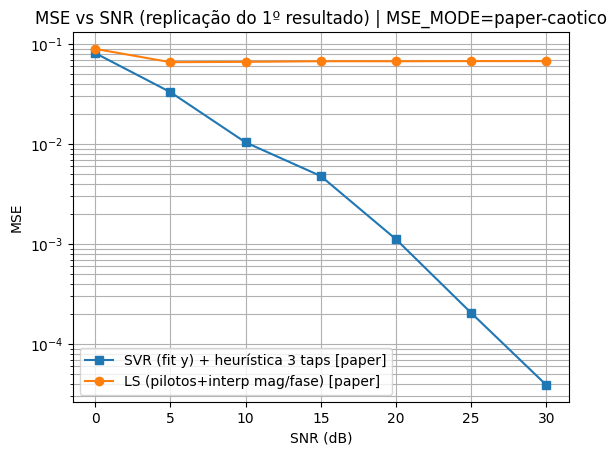

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# Objetivo: reproduzir o "modo caótico" do 1º código
#           (o mesmo MSE e o mesmo lugar do abs())
# ============================================================

# -----------------------------
# Configuração
# -----------------------------
K = 16          # subportadoras
CP = 0          # sem CP
P0 = 4          # pilotos "base" (antes do +1 do último carrier)
pilotValue = 3 + 3j
SB = 10         # símbolos de dados por frame
mu = 4          # 16-QAM

DD = list(range(35))
D = DD[::5]     # SNRs: 0,5,10,15,20,25,30
amostras = 1000 # igual ao seu 1º script

# IMPORTANTE: para bater com o 1º script, não fixe seed.
# np.random.seed(42)

# -----------------------------
# Carriers / pilotos
# -----------------------------
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                  # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                   # agora P=5
dataCarriers = np.delete(allCarriers, pilotCarriers)

payloadBits_per_OFDM = len(dataCarriers) * mu

# -----------------------------
# Mapping 16-QAM (igual ao seu)
# -----------------------------
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}

# -----------------------------
# Canal "verdadeiro" (igual ao seu)
# -----------------------------
channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# Funções auxiliares
# ============================================================
def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):
    return np.fft.fft(x)

def IDFT(X):
    return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    # symbols_1d tem tamanho SB*K
    return symbols_1d.reshape((SB, K))

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full" (igual ao seu)
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j * np.random.randn(*convolved.shape))
    return convolved + noise

# ============================================================
# Features no tempo para SVR (igual ao paper/código original)
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2 * np.pi / K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# Heurística 3 taps (igual ao seu)
# Entrada: H_est_time (K,)
# Saída: Hest_freq (K,)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    # mesma "compressão" do seu código
    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    # usei arctan2 (mais estável), mas mantém a ideia
    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2) * (1 / 5.7) * np.abs(H_est_t[0]) * np.exp(1j * (fase[0] - np.pi / 4.5)),
        (1 / 4) * H_est_t[1],
        np.sqrt(2) * (1 / 5) * H_est_t[2] * np.exp(1j * (fase[0] - np.pi / 2 + np.pi / 25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    Hest = np.fft.fft(H_est_T, K)
    return Hest

# ============================================================
# LS do "paper": pilotos + interp mag/fase (igual ao seu)
# ============================================================
def channelEstimate_LS_article(OFDM_demod):
    pilots = OFDM_demod[pilotCarriers]
    Hest_at_pilots = pilots / pilotValue

    Hest_abs = scipy.interpolate.interp1d(
        pilotCarriers, np.abs(Hest_at_pilots), kind="linear",
    )(allCarriers)

    Hest_phase = scipy.interpolate.interp1d(
        pilotCarriers, np.angle(Hest_at_pilots), kind="linear",
    )(allCarriers)

    return Hest_abs * np.exp(1j * Hest_phase)

# ============================================================
# MSE "CAÓTICO" (o do seu 1º código)
#   - por amostra: mean((H-Hest)^2)  -> COMPLEXO
#   - por SNR: abs(mean_over_samples(...))  -> abs só no final
# ============================================================
def mse_like_first_code_complex(H_true, H_est):
    return np.mean((H_true - H_est) ** 2)  # complexo!

# ============================================================
# Simulação
# ============================================================
Im_media = []    # SVR + heurística (abs só no final)
Imls_media = []  # LS (abs só no final)

for SNRdb in D:
    Im = []    # lista de MSE complexos (SVR)
    Imls = []  # lista de MSE complexos (LS)

    for _ in range(amostras):
        # --------------------------
        # Gera SB símbolos de dados
        # --------------------------
        OFDM_block = []
        for _sb in range(SB):
            bits = np.random.binomial(n=1, p=0.5, size=(payloadBits_per_OFDM,))
            QAM = Mapping(SP(bits))
            OFDM_data = OFDM_symbol(QAM)
            OFDM_time = IDFT(OFDM_data)
            OFDM_block.append(OFDM_time)

        OFDM_block = np.concatenate(OFDM_block)

        # --------------------------
        # Preambulo (2 símbolos)
        # --------------------------
        OFDM_pilot = OFDM_symbol_p()
        OFDM_time_pilot = IDFT(OFDM_pilot)
        OFDM_preamble = np.concatenate((OFDM_time_pilot, OFDM_time_pilot))

        # Frame completo
        BLOCK = np.concatenate((OFDM_preamble, OFDM_block), 0)

        # Canal
        RECEIVED_BLOCK = channel(BLOCK, SNRdb)

        # ======================================================
        # (A) SVR do paper: usa o 2º símbolo do preâmbulo (K:2K)
        # ======================================================
        y_re = RECEIVED_BLOCK[K:2*K].real
        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y_re)
        H_est_re = svr_re.predict(pilots_at_time_real)

        y_im = RECEIVED_BLOCK[K:2*K].imag
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im.fit(pilots_at_time_imag, y_im)
        H_est_im = svr_im.predict(pilots_at_time_imag)

        H_est_time = (H_est_re + 1j * H_est_im)
        Hest_svr = heuristic_3taps_from_time(H_est_time)

        Im.append(mse_like_first_code_complex(H_exact, Hest_svr))

        # ======================================================
        # (B) LS do paper: usa símbolos de DADOS (2K : 12K)
        # ======================================================
        RECEIVED_PACKAGE = RECEIVED_BLOCK[2*K : (2+SB)*K]   # 2K até 12K (SB=10)
        received_OFDM = SP_carrier(RECEIVED_PACKAGE)        # (SB, K)
        received_OFDM = np.array(received_OFDM).T           # (K, SB)

        # no seu código LS você calcula MSE por símbolo e depois média
        mse_ls_per_symbol = []
        for sb in range(SB):
            OFDM_S = received_OFDM[:, sb]
            OFDM_demod = DFT(OFDM_S)
            Hest_ls = channelEstimate_LS_article(OFDM_demod)
            mse_ls_per_symbol.append(mse_like_first_code_complex(H_exact, Hest_ls))

        Imls.append(np.mean(mse_ls_per_symbol))  # ainda complexo

    # ABS SÓ AQUI (igual ao 1º script)
    Im_media.append(np.abs(np.mean(Im)))
    Imls_media.append(np.abs(np.mean(Imls)))

    print(f"SNR={SNRdb:>2} dB | SVR+heur={Im_media[-1]:.4e} | LS={Imls_media[-1]:.4e}")

# ============================================================
# Plot (ordem igual ao seu 1º plot: SVR primeiro, LS depois)
# ============================================================
plt.figure()
plt.semilogy(D, Im_media, marker="s")
plt.semilogy(D, Imls_media, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("MSE")
plt.title("MSE vs SNR (replicação do 1º resultado) | MSE_MODE=paper-caotico")
plt.legend([
    "SVR (fit y) + heurística 3 taps [paper]",
    "LS (pilotos+interp mag/fase) [paper]",
])
plt.show()

SNR= 0 dB | SVR+heur=8.0450e-01 | heu-only=9.4374e-01 | LS=6.9446e-01
SNR= 5 dB | SVR+heur=2.6666e-01 | heu-only=3.0846e-01 | LS=2.7301e-01
SNR=10 dB | SVR+heur=8.5302e-02 | heu-only=1.1151e-01 | LS=1.4574e-01
SNR=15 dB | SVR+heur=2.9980e-02 | heu-only=4.9690e-02 | LS=1.0784e-01
SNR=20 dB | SVR+heur=9.8160e-03 | heu-only=3.0754e-02 | LS=9.5895e-02
SNR=25 dB | SVR+heur=3.0262e-03 | heu-only=2.4168e-02 | LS=9.2099e-02
SNR=30 dB | SVR+heur=1.0215e-03 | heu-only=2.2321e-02 | LS=9.0902e-02


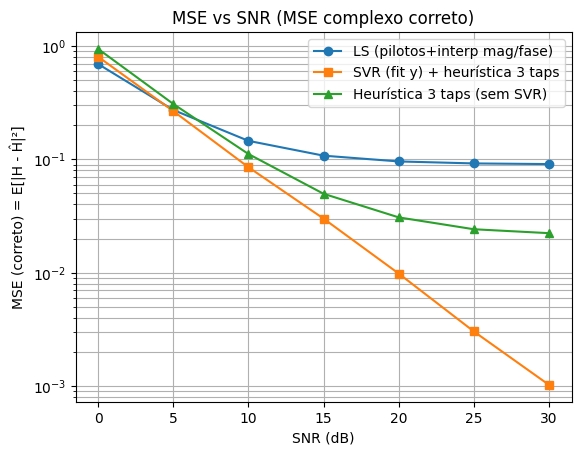

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# OFDM + estimação de canal (SVR + heurística 3 taps) vs LS
# MSE CORRETO para complexo:  E[ |H - Hhat|^2 ]
# ============================================================

# -----------------------------
# Parâmetros do sistema
# -----------------------------
K = 16          # subportadoras
CP = 0          # sem CP
P0 = 4          # número "base" de pilotos (antes de adicionar o último carrier)
pilotValue = 3 + 3j
SB = 10         # símbolos de dados por frame
mu = 4          # 16-QAM
amostras = 5000

DD = list(range(35))
D = DD[::5]     # 0,5,10,15,20,25,30 dB

# Se quiser reprodutibilidade, descomente:
# np.random.seed(42)

# -----------------------------
# Carriers / pilotos
# -----------------------------
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                  # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                   # agora P=5
dataCarriers = np.delete(allCarriers, pilotCarriers)

payloadBits_per_OFDM = len(dataCarriers) * mu

# -----------------------------
# Mapping 16-QAM
# -----------------------------
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}

# -----------------------------
# Canal "verdadeiro"
# -----------------------------
channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# Funções auxiliares
# ============================================================
def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):
    return np.fft.fft(x)

def IDFT(X):
    return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    return symbols_1d.reshape((SB, K))

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full"
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j * np.random.randn(*convolved.shape))
    return convolved + noise

# ✅ MSE correto para complexo
def mse_correct(H_true, H_est):
    return np.mean(np.abs(H_true - H_est) ** 2)

# ============================================================
# Features no tempo para SVR (igual ao paper)
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2 * np.pi / K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# Heurística 3 taps (como no paper/código original)
# Entrada: vetor complexo no tempo (K,)
# Saída: Hest em frequência (K,)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    # arctan2 é mais estável que arctan(im/re), mas mantém a ideia
    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2) * (1 / 5.7) * np.abs(H_est_t[0]) * np.exp(1j * (fase[0] - np.pi / 4.5)),
        (1 / 4) * H_est_t[1],
        np.sqrt(2) * (1 / 5) * H_est_t[2] * np.exp(1j * (fase[0] - np.pi / 2 + np.pi / 25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    return np.fft.fft(H_est_T, K)

# ============================================================
# LS do paper: pilotos + interpolação em magnitude e fase
# ============================================================
def channelEstimate_LS_article(OFDM_demod):
    pilots = OFDM_demod[pilotCarriers]
    Hest_at_pilots = pilots / pilotValue

    Hest_abs = scipy.interpolate.interp1d(
        pilotCarriers, np.abs(Hest_at_pilots), kind="linear"
    )(allCarriers)

    Hest_phase = scipy.interpolate.interp1d(
        pilotCarriers, np.angle(Hest_at_pilots), kind="linear"
    )(allCarriers)

    return Hest_abs * np.exp(1j * Hest_phase)

# ============================================================
# Simulação
# ============================================================
mse_svr_media = []
mse_ls_media = []
mse_heu_media = []  # baseline: heurística direto no y (sem SVR)

for SNRdb in D:
    mse_svr = []
    mse_ls = []
    mse_heu = []

    for _ in range(amostras):
        # --------------------------
        # Gera SB símbolos de dados
        # --------------------------
        OFDM_block = []
        for _sb in range(SB):
            bits = np.random.binomial(n=1, p=0.5, size=(payloadBits_per_OFDM,))
            QAM = Mapping(SP(bits))
            OFDM_data = OFDM_symbol(QAM)
            OFDM_time = IDFT(OFDM_data)
            OFDM_block.append(OFDM_time)

        OFDM_block = np.concatenate(OFDM_block)

        # --------------------------
        # Preambulo (2 símbolos)
        # --------------------------
        OFDM_pilot = OFDM_symbol_p()
        OFDM_time_pilot = IDFT(OFDM_pilot)
        OFDM_preamble = np.concatenate((OFDM_time_pilot, OFDM_time_pilot))

        BLOCK = np.concatenate((OFDM_preamble, OFDM_block), 0)
        RECEIVED_BLOCK = channel(BLOCK, SNRdb)

        # ======================================================
        # (A) SVR: usa o 2º símbolo do preâmbulo (K:2K)
        # ======================================================
        y_re = RECEIVED_BLOCK[K:2*K].real
        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y_re)
        H_est_re = svr_re.predict(pilots_at_time_real)

        y_im = RECEIVED_BLOCK[K:2*K].imag
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im.fit(pilots_at_time_imag, y_im)
        H_est_im = svr_im.predict(pilots_at_time_imag)

        H_est_time = H_est_re + 1j * H_est_im
        Hest_svr = heuristic_3taps_from_time(H_est_time)
        mse_svr.append(mse_correct(H_exact, Hest_svr))

        # ======================================================
        # (B) Baseline: heurística direto no y (sem SVR)
        # ======================================================
        y_time = RECEIVED_BLOCK[K:2*K]
        Hest_heu = heuristic_3taps_from_time(y_time)
        mse_heu.append(mse_correct(H_exact, Hest_heu))

        # ======================================================
        # (C) LS: usa símbolos de DADOS (2K : 12K)
        # ======================================================
        RECEIVED_PACKAGE = RECEIVED_BLOCK[2*K : (2+SB)*K]
        received_OFDM = SP_carrier(RECEIVED_PACKAGE)  # (SB, K)
        received_OFDM = received_OFDM.T               # (K, SB)

        mse_ls_sb = []
        for sb in range(SB):
            OFDM_S = received_OFDM[:, sb]
            OFDM_demod = DFT(OFDM_S)
            Hest_ls = channelEstimate_LS_article(OFDM_demod)
            mse_ls_sb.append(mse_correct(H_exact, Hest_ls))

        mse_ls.append(np.mean(mse_ls_sb))

    mse_svr_media.append(np.mean(mse_svr))
    mse_heu_media.append(np.mean(mse_heu))
    mse_ls_media.append(np.mean(mse_ls))

    print(f"SNR={SNRdb:>2} dB | SVR+heur={mse_svr_media[-1]:.4e} | heu-only={mse_heu_media[-1]:.4e} | LS={mse_ls_media[-1]:.4e}")

# ============================================================
# Plot
# ============================================================
plt.figure()
plt.semilogy(D, mse_ls_media, marker="o")
plt.semilogy(D, mse_svr_media, marker="s")
plt.semilogy(D, mse_heu_media, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("MSE (correto) = E[|H - Ĥ|²]")
plt.title("MSE vs SNR (MSE complexo correto)")
plt.legend([
    "LS (pilotos+interp mag/fase)",
    "SVR (fit y) + heurística 3 taps",
    "Heurística 3 taps (sem SVR)"
])
plt.show()

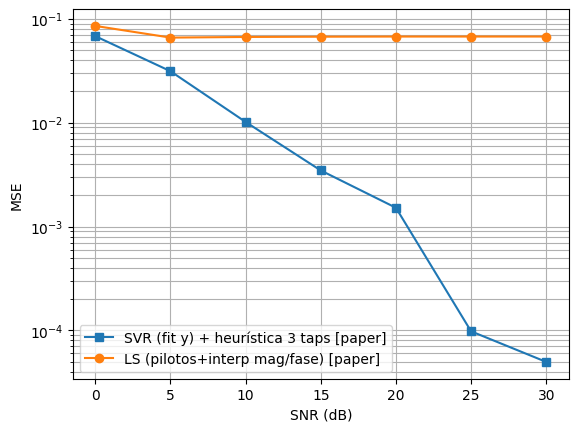

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import cmath
from __future__ import annotations

import copy
import numbers
from typing import Sequence, Mapping, List, Tuple, NoReturn

K = 16 # number of subcarriers.

CP = 0 # K//4 # cyclic prefix length.

P = 4 # number of pilot subcarriers.

pilotValue = 3+3j # pilot value.

allCarriers = np.arange(K)  # array with indices of all subcarriers ([0, 1, ... K-1]).

pilotCarriers = allCarriers[::K//P] # Pilots are all (K/P)th carriers.

pilotCarriers = np.hstack([pilotCarriers, np.array([allCarriers[-1]])]) 

P = P+1 

dataCarriers = np.delete(allCarriers, pilotCarriers) # de allCarriers tirar pilotCarriers.

############################################################################################################
SB = 10 # number of symbol per OFDM block
mu = 4 # bits per symbol (i.e. 16QAM)

payloadBits_per_OFDM = len(dataCarriers)*mu  # number of payload bits per OFDM symbol

mapping_table = {
    (0,0,0,0) : -3-3j,
    (0,0,0,1) : -3-1j,
    (0,0,1,0) : -3+3j,
    (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j,
    (0,1,0,1) : -1-1j,
    (0,1,1,0) : -1+3j,
    (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j,
    (1,0,0,1) :  3-1j,
    (1,0,1,0) :  3+3j,
    (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j,
    (1,1,0,1) :  1-1j,
    (1,1,1,0) :  1+3j,
    (1,1,1,1) :  1+1j
}
for b3 in [0, 1]:
    for b2 in [0, 1]:
        for b1 in [0, 1]:
            for b0 in [0, 1]:
                B = (b3, b2, b1, b0)
                Q = mapping_table[B]

demapping_table = {v : k for k, v in mapping_table.items()}

############################################################################################################

channelResponse = np.array([1, 0, 0.3+0.3j])  # channel impulse response.

H_exact = np.fft.fft(channelResponse, K) 


############################################################################################################

Im_media = []

Imls_media = []

qIm_media = []

DD = list(range(35))
D = DD[::5]
amostras = 1000

############################################################################################################

def SP(bits):
    return bits.reshape((len(dataCarriers), mu)) # 48 (192/4) linhas com mu=4 elementos em cada linha. matriz 48 X 4.

############################################################################################################

def SP_carrier(symbols):
    return symbols.reshape((SB, K))

############################################################################################################

def Mapping(bits):
    return np.array([mapping_table[tuple(b)] for b in bits])

############################################################################################################

def OFDM_symbol_p(Pilot_payload):
    symbol_p = np.zeros(K, dtype=complex) # matriz 1 X 64 nula
    symbol_p[pilotCarriers] = pilotValue  # alocando o valor conhecido 3+3j dos pilotos na matriz nula nas posições dos índices dos pilotos.
    return symbol_p 

############################################################################################################

def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=complex) # matriz 1 X K nula 
    symbol[pilotCarriers] = pilotValue  # alocando o valor conhecido 3+3j dos pilotos na matriz nula nas posições dos índices dos pilotos.
    symbol[dataCarriers] = QAM_payload  # alocando QAM na matriz nula nas posições dos índices dos dados.
    return symbol

############################################################################################################

def DFT(OFDM_RX):
            return np.fft.fft(OFDM_RX)

###########################################################################################################

def IDFT(OFDM):
    return np.fft.ifft(OFDM) # aplica IDFT na símbolo OFDM 1 X 64.

############################################################################################################

def equalize(OFDM_freq, Hest):
    return OFDM_freq / Hest

###########################################################################################################

def get_payload(equalized):
    return equalized[dataCarriers]

###########################################################################################################

def Demapping(QAM):
             constellation = np.array([x for x in demapping_table.keys()])
    
             dists = abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    
             const_index = dists.argmin(axis=1)
    
             hardDecision = constellation[const_index]
             return np.vstack([demapping_table[C] for C in hardDecision]), hardDecision
        
############################################################################################################

def PS(bits):
            return bits.reshape((-1,))

############################################################################################################
for SNRdb in D:
    Im = []
    for i in range(amostras):
        bits_t = []
        OFDM_block = []
        for sb in range(SB):
            bits = np.random.binomial(n=1, p=0.5, size=(payloadBits_per_OFDM, )) 
            bits_SP = SP(bits)
            bits_t.append(bits) 
            QAM = Mapping(bits_SP)
            OFDM_data = OFDM_symbol(QAM)
            OFDM_time = IDFT(OFDM_data)
            OFDM_block.append(OFDM_time) 
        bits_t = np.concatenate(bits_t)
        OFDM_block = np.concatenate(OFDM_block)
    
    #print('OFDM_block:',OFDM_block)
    #print(len(OFDM_block))

#############################################################################################################

        OFDM_pilot = OFDM_symbol_p(QAM)
        OFDM_time_pilot = IDFT(OFDM_pilot)
        OFDM_preamble = np.concatenate((OFDM_time_pilot, OFDM_time_pilot))
    #print('OFDM_preamble:',OFDM_preamble,'\n')
    #print(len(OFDM_preamble))
    
#############################################################################################################

        BLOCK = np.concatenate((OFDM_preamble, OFDM_block), 0)
    
########################################### DEFINIÇÃO DO CANAL ##############################################
#    for SNRdb in D:
#        Im = []
            
        def channel(signal):
            convolved = np.convolve(signal, channelResponse)
            signal_power = np.mean(abs(convolved**2))
            sigma2 = signal_power * 10**(-SNRdb/10)  # calcula variância do ruído com base na potência do sinal e SNR
            noise = np.sqrt(sigma2/2) * (np.random.randn(*convolved.shape)+1j*np.random.randn(*convolved.shape))
            return convolved + noise

        RECEIVED_BLOCK = channel(BLOCK)
        #print('RECEIVED_BLOCK:',RECEIVED_BLOCK)
        #print(len(RECEIVED_BLOCK))
        
################################################# SVR REAL #################################################

        y_re = RECEIVED_BLOCK[K:2*K].real

        y = np.array( y_re )

        pilots_at_time_real = np.zeros((K,P)) # matriz 64 X 64 nula

        for j in range(P):
            pilots_at_time_real[:,j]= ((pilotValue)*np.exp(1j*2*np.pi/K*pilotCarriers[j]*allCarriers)).real
        
        svr = SVR(kernel="rbf", C=100, gamma="auto")

        svr.fit(pilots_at_time_real,y)

        H_est_re = svr.predict(pilots_at_time_real)#.reshape(-1,64))

#################################################### SVR IM ################################################

        y_im = RECEIVED_BLOCK[K:2*K].imag 

        y = np.array(y_im)

        pilots_at_time_imag = np.zeros((K,P)) # matriz 64 X 64 nula

        for j in range(P):
            pilots_at_time_imag[:,j]=(pilotValue*np.exp(1j*2*np.pi/K*pilotCarriers[j]*allCarriers)).imag
  
        svr = SVR(kernel="rbf", C=100, gamma="auto")

        svr.fit(pilots_at_time_imag,y)

        H_est_im = svr.predict(pilots_at_time_imag)#.reshape(-1,64))

############################################ ESTIMAÇÃO DO CANAL ############################################

        H_est = (H_est_re+1j*H_est_im)

        H_est_t=(H_est[np.arange(0,3)]+ H_est[np.arange(4,7)]+ H_est[np.arange(8,11)]+ H_est[np.arange(12,15)])

        fase = np.arctan(H_est_t.imag/H_est_t.real)

        H_est_T1 = [np.sqrt(2)*1/5.7*abs(H_est_t[0])* np.exp(1j*(fase[0]-np.pi/4.5)), 1/4*H_est_t[1], np.sqrt(2)*1/5*H_est_t[2]* np.exp(1j*(fase[0]-np.pi/2+np.pi/25))]

        c=H_est_T1[1]

        H_est_T= np.array(H_est_T1)-c

        H_est_freq = np.fft.fft(H_est_T,K)

        Hest = H_est_freq
        
############################################################################################################
     
#        RECEIVED_PACKAGE = RECEIVED_BLOCK[2*K:12*K]
#        received_OFDM = SP_carrier(RECEIVED_PACKAGE)
#        received_OFDM = np.array(received_OFDM).T
#        bits_r = []
#        for sb in range(SB):
#            OFDM_S = received_OFDM[:,sb]
#            OFDM_freq = DFT(OFDM_S)

############################################################################################################

#            equalized_Hest = equalize(OFDM_freq, Hest)
            
#############################################################################################################
            
#            QAM_est = get_payload(equalized_Hest)
    
#############################################################################################################

#            PS_est, hardDecision = Demapping(QAM_est)
            
#############################################################################################################

#            bits_est = PS(PS_est)
#            bits_r.append(bits_est)
#        bits_r = np.concatenate(bits_r)
###################################################### BER ##################################################
        MSE = np.sum((H_exact - Hest)**2)/len(H_exact) # reduzir SNR para ter erros.

        Im.append(MSE)
    
    MSE_media = np.mean(Im)
    
    Im_media.append(abs(MSE_media))
#    print(bits_t)
#    print(bits_r)
#    print(MSE)

##################################################### LS ####################################################
#def addCP(OFDM_time):
#    cp = OFDM_time[-CP:]               # take the last CP samples ...
#    return np.hstack([cp, OFDM_time])  # ... and add them to the beginning
#OFDM_withCP = addCP(OFDM_time)


for SNRdb in D:
    
    Imls = []
    
    for i in range(amostras):
        
        bits_t = []
        OFDM_block = []
        for sb in range(SB):
            bits = np.random.binomial(n=1, p=0.5, size=(payloadBits_per_OFDM, )) 
            bits_SP = SP(bits)
            bits_t.append(bits) 
            QAM = Mapping(bits_SP)
            OFDM_data = OFDM_symbol(QAM)
            OFDM_time = IDFT(OFDM_data)
            OFDM_block.append(OFDM_time) 
        bits_t = np.concatenate(bits_t)
        OFDM_block = np.concatenate(OFDM_block)
    
    #print('OFDM_block:',OFDM_block)
    #print(len(OFDM_block))

#############################################################################################################

        OFDM_pilot = OFDM_symbol_p(QAM)
        OFDM_time_pilot = IDFT(OFDM_pilot)
        OFDM_preamble = np.concatenate((OFDM_time_pilot, OFDM_time_pilot))
    #print('OFDM_preamble:',OFDM_preamble,'\n')
    #print(len(OFDM_preamble))
    
#############################################################################################################

        BLOCK = np.concatenate((OFDM_preamble, OFDM_block), 0)
    
        def channel(signal):
            convolved = np.convolve(signal, channelResponse)
            signal_power = np.mean(abs(convolved**2))
            sigma2 = signal_power * 10**(-SNRdb/10)
            noise = np.sqrt(sigma2/2) * (np.random.randn(*convolved.shape)+1j*np.random.randn(*convolved.shape))
            return convolved + noise
        
        RECEIVED_BLOCK = channel(BLOCK)
     ###
#        OFDM_TX = OFDM_withCP
#        OFDM_RX = channel(OFDM_TX)

#        def removeCP(signal):
#            return signal[CP:(CP+K)]
    
#        OFDM_RX_noCP = removeCP(OFDM_RX)
        
    
#        def DFT(OFDM_RX):
#            return np.fft.fft(OFDM_RX)
        RECEIVED_PACKAGE = RECEIVED_BLOCK[2*K:12*K]
        received_OFDM = SP_carrier(RECEIVED_PACKAGE)
        received_OFDM = np.array(received_OFDM).T
        MSE_ls = []
        for sb in range(SB):
            OFDM_S = received_OFDM[:,sb]
            OFDM_demod = DFT(OFDM_S)
            #OFDM_demod = DFT(OFDM_RX_noCP)
            def channelEstimate(OFDM_demod):
                pilots = OFDM_demod[pilotCarriers]  
                Hest_at_pilots = pilots / pilotValue
                Hest_abs = scipy.interpolate.interp1d(pilotCarriers, abs(Hest_at_pilots), kind='linear')(allCarriers)
                Hest_phase = scipy.interpolate.interp1d(pilotCarriers, np.angle(Hest_at_pilots), kind='linear')(allCarriers)
                Hest = Hest_abs * np.exp(1j*Hest_phase)
                return Hest

            Hest = channelEstimate(OFDM_demod)
            #def equalize(OFDM_demod, Hest):
                #return OFDM_demod / Hest
    
#            equalized_Hest = equalize(OFDM_demod, Hest)
    
            #def get_payload(equalized):
                #return equalized[dataCarriers]
    
#            QAM_est = get_payload(equalized_Hest)
    
            #def Demapping(QAM):
             #   constellation = np.array([x for x in demapping_table.keys()])
             #   dists = abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
             #   const_index = dists.argmin(axis=1)
             #   hardDecision = constellation[const_index]
             #   return np.vstack([demapping_table[C] for C in hardDecision]), hardDecision
  
 #            PS_est, hardDecision = Demapping(QAM_est)
    
#            bits_est = PS(PS_est)
#            bits_r.append(bits_est)
#        bits_r = np.concatenate(bits_r)
    
            MSE = np.sum((H_exact - Hest)**2)/len(H_exact) # reduzir SNR para ter erros.
            MSE_ls.append(MSE) 
        MSE_media = np.mean(MSE_ls)
        Imls.append(MSE_media)
    
    MSE_media_ls = np.mean(Imls)
    
    Imls_media.append(abs(MSE_media_ls))
    #print(bits_t)

plt.figure()
plt.semilogy(D, Im_media, marker="s")
plt.semilogy(D, Imls_media, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("MSE")
#plt.title(f"MSE vs SNR (replicação paper) | MSE_MODE={MSE_MODE}")
plt.legend([
    "SVR (fit y) + heurística 3 taps [paper]",
    "LS (pilotos+interp mag/fase) [paper]",
])
plt.show()

SNR= 0 dB | CH(paper) SVR=7.340e-02 LS=8.840e-02 | PAY MSE SVR=1.526e+02 LS=2.074e+01 | PHI RMSE SVR=8.040e-01 LS=6.380e-01 | BER SVR=3.802e-01 LS=3.559e-01
SNR= 5 dB | CH(paper) SVR=3.198e-02 LS=6.744e-02 | PAY MSE SVR=4.945e+01 LS=7.734e+00 | PHI RMSE SVR=4.115e-01 LS=3.895e-01 | BER SVR=2.599e-01 LS=2.455e-01
SNR=10 dB | CH(paper) SVR=8.653e-03 LS=6.710e-02 | PAY MSE SVR=5.386e+00 LS=3.110e+00 | PHI RMSE SVR=2.062e-01 LS=2.724e-01 | BER SVR=1.413e-01 LS=1.527e-01
SNR=15 dB | CH(paper) SVR=3.472e-03 LS=6.744e-02 | PAY MSE SVR=1.536e+00 LS=1.795e+00 | PHI RMSE SVR=1.128e-01 LS=2.322e-01 | BER SVR=6.040e-02 LS=1.011e-01
SNR=20 dB | CH(paper) SVR=1.114e-03 LS=6.754e-02 | PAY MSE SVR=7.186e-01 LS=1.397e+00 | PHI RMSE SVR=6.349e-02 LS=2.185e-01 | BER SVR=2.575e-02 LS=7.979e-02
SNR=25 dB | CH(paper) SVR=6.564e-05 LS=6.745e-02 | PAY MSE SVR=4.836e-01 LS=1.271e+00 | PHI RMSE SVR=3.643e-02 LS=2.142e-01 | BER SVR=1.479e-02 LS=7.249e-02
SNR=30 dB | CH(paper) SVR=4.283e-05 LS=6.768e-02 | PAY MSE

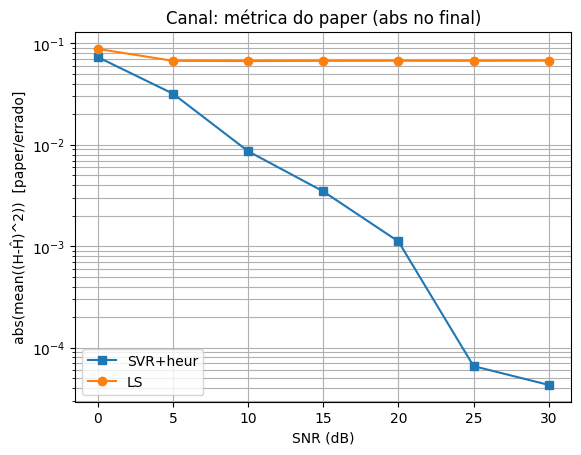

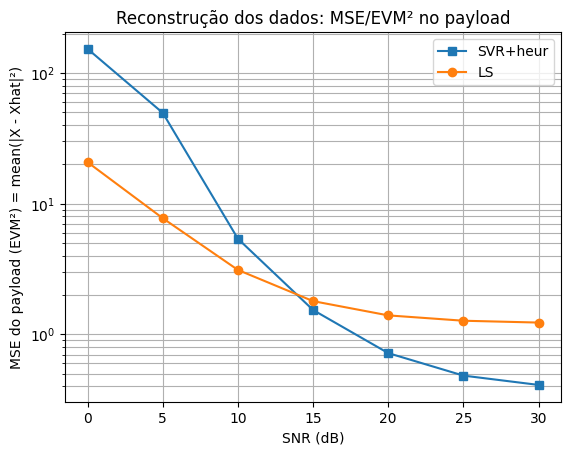

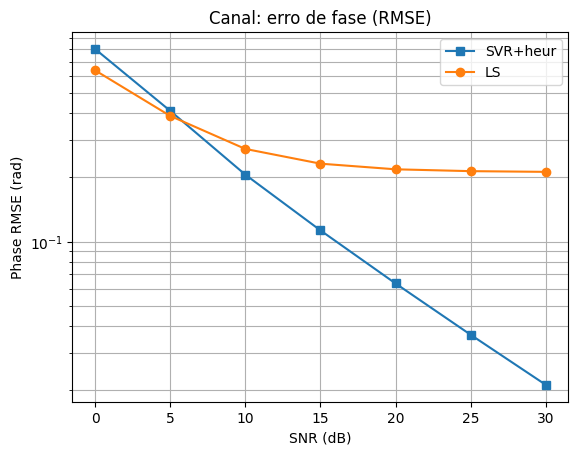

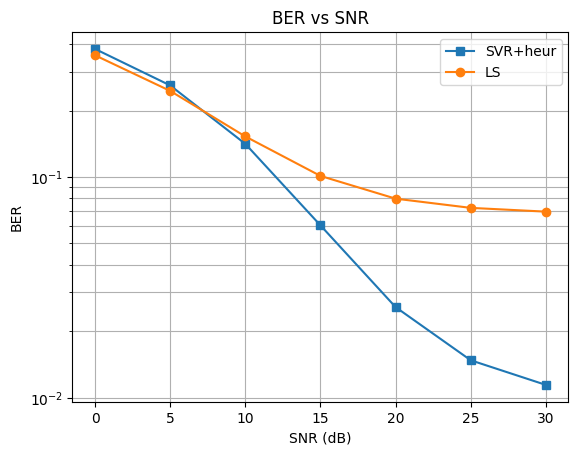

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# Configuração
# ============================================================
K = 16
CP = 0
P0 = 4
pilotValue = 3 + 3j
SB = 10
mu = 4
amostras = 2000  # ajuste como quiser (5000 pode ficar pesado)

DD = list(range(35))
D = DD[::5]  # 0,5,10,15,20,25,30 dB

# Se quiser reprodutibilidade:
# np.random.seed(42)

# ============================================================
# Carriers / pilotos
# ============================================================
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                 # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                  # 5
dataCarriers = np.delete(allCarriers, pilotCarriers)
payloadBits_per_OFDM = len(dataCarriers) * mu

# ============================================================
# 16-QAM mapping/demapping
# ============================================================
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}
demapping_table = {v: k for k, v in mapping_table.items()}
constellation = np.array(list(demapping_table.keys()))

def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def PS(bits2d):
    return bits2d.reshape((-1,))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def Demapping(QAM):
    dists = np.abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    const_index = dists.argmin(axis=1)
    hardDecision = constellation[const_index]
    bits_hat = np.vstack([demapping_table[c] for c in hardDecision])
    return bits_hat, hardDecision

# ============================================================
# Canal verdadeiro
# ============================================================
channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# OFDM helpers
# ============================================================
def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):  return np.fft.fft(x)
def IDFT(X): return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    return symbols_1d.reshape((SB, K))  # (SB, K)

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full"
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j*np.random.randn(*convolved.shape))
    return convolved + noise

# ============================================================
# Features tempo para SVR (iguais ao paper)
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2*np.pi/K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# Heurística 3 taps (paper)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    # (pode usar arctan como no seu, mas arctan2 é mais estável)
    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2)*(1/5.7)*np.abs(H_est_t[0]) * np.exp(1j*(fase[0] - np.pi/4.5)),
        (1/4)*H_est_t[1],
        np.sqrt(2)*(1/5)*H_est_t[2] * np.exp(1j*(fase[0] - np.pi/2 + np.pi/25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    return np.fft.fft(H_est_T, K)

# ============================================================
# LS (paper): interp mag/fase
# ============================================================
def channelEstimate_LS_article(OFDM_demod):
    pilots = OFDM_demod[pilotCarriers]
    Hest_at_pilots = pilots / pilotValue

    Hest_abs = scipy.interpolate.interp1d(
        pilotCarriers, np.abs(Hest_at_pilots), kind="linear"
    )(allCarriers)

    Hest_phase = scipy.interpolate.interp1d(
        pilotCarriers, np.angle(Hest_at_pilots), kind="linear"
    )(allCarriers)

    return Hest_abs * np.exp(1j * Hest_phase)

# ============================================================
# Métricas
# ============================================================
# (1) "MSE errado do paper" por amostra: COMPLEXO
def mse_paper_complex(H_true, H_est):
    return np.mean((H_true - H_est) ** 2)  # complexo

# (2) Reconstrução do payload: MSE correto (energia)
def mse_payload(QAM_true, QAM_hat):
    return np.mean(np.abs(QAM_true - QAM_hat) ** 2)

# (3) Erro de fase do CANAL (rad): usa diferença angular correta
def phase_rmse(H_true, H_est, eps=1e-12):
    mask = np.abs(H_true) > eps
    # diferença angular envolvida em [-pi, pi]
    dphi = np.angle(H_true[mask] * np.conj(H_est[mask]))
    return np.sqrt(np.mean(dphi**2))

# ============================================================
# Simulação
# ============================================================
# Curvas do CANAL
mse_ch_svr = []
mse_ch_ls  = []

# Curvas de RECONSTRUÇÃO (payload)
mse_pay_svr = []
mse_pay_ls  = []

# Curvas de FASE do canal
phi_svr = []
phi_ls  = []

# (opcional) BER
ber_svr = []
ber_ls  = []

for SNRdb in D:
    # acumula por amostra
    mse_ch_svr_samples = []
    mse_ch_ls_samples  = []

    mse_pay_svr_samples = []
    mse_pay_ls_samples  = []

    phi_svr_samples = []
    phi_ls_samples  = []

    ber_svr_samples = []
    ber_ls_samples  = []

    for _ in range(amostras):
        # --------------------------
        # Gera dados (SB símbolos)
        # --------------------------
        bits_tx_all = []
        QAM_tx_all = []      # payload (só dataCarriers)
        OFDM_tx_time = []

        for _sb in range(SB):
            bits = np.random.binomial(1, 0.5, size=(payloadBits_per_OFDM,))
            bits_tx_all.append(bits)

            qam = Mapping(SP(bits))
            QAM_tx_all.append(qam)

            X = OFDM_symbol(qam)
            x = IDFT(X)
            OFDM_tx_time.append(x)

        bits_tx_all = np.concatenate(bits_tx_all)
        OFDM_tx_time = np.concatenate(OFDM_tx_time)

        # --------------------------
        # Preâmbulo (2 símbolos)
        # --------------------------
        Xp = OFDM_symbol_p()
        xp = IDFT(Xp)
        preamble = np.concatenate([xp, xp])

        # Frame completo
        tx_frame = np.concatenate([preamble, OFDM_tx_time])
        rx_frame = channel(tx_frame, SNRdb)

        # ======================================================
        # Estimação SVR (1 vez pelo 2º símbolo do preâmbulo)
        # ======================================================
        y2 = rx_frame[K:2*K]  # 2º símbolo do preâmbulo no tempo

        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y2.real)
        svr_im.fit(pilots_at_time_imag, y2.imag)

        H_est_time = svr_re.predict(pilots_at_time_real) + 1j*svr_im.predict(pilots_at_time_imag)
        Hest_svr = heuristic_3taps_from_time(H_est_time)

        # ======================================================
        # Recebe pacote de dados (SB símbolos)
        # ======================================================
        rx_data = rx_frame[2*K:(2+SB)*K]    # 2K .. 12K
        rx_mat = SP_carrier(rx_data).T      # (K, SB)

        # ====== Reconstrução com SVR (mesmo H para todos)
        QAM_hat_all_svr = []
        bits_hat_all_svr = []
        for sb in range(SB):
            Y = DFT(rx_mat[:, sb])
            Yeq = Y / (Hest_svr)          # equalização
            qam_hat = Yeq[dataCarriers]           # payload estimado
            QAM_hat_all_svr.append(qam_hat)

            b2d, _ = Demapping(qam_hat)
            bits_hat_all_svr.append(PS(b2d))

        bits_hat_all_svr = np.concatenate(bits_hat_all_svr)

        # MSE payload SVR (correto)
        qam_true = np.concatenate(QAM_tx_all)
        qam_hat_svr = np.concatenate(QAM_hat_all_svr)
        mse_pay_svr_samples.append(mse_payload(qam_true, qam_hat_svr))

        # BER SVR
        ber_svr_samples.append(np.mean(bits_tx_all != bits_hat_all_svr))

        # Métricas do canal SVR
        mse_ch_svr_samples.append(mse_paper_complex(H_exact, Hest_svr))  # complexo (paper)
        phi_svr_samples.append(phase_rmse(H_exact, Hest_svr))

        # ======================================================
        # LS (por símbolo, como no seu LS)
        # ======================================================
        # Para ser "justo", vamos:
        # - calcular um Hest_ls por símbolo
        # - equalizar esse símbolo com seu Hest_ls
        # - acumular MSE de payload e fase por símbolo
        mse_ch_ls_symbol = []
        phi_ls_symbol = []
        qam_hat_ls_all = []
        bits_hat_ls_all = []

        for sb in range(SB):
            Y = DFT(rx_mat[:, sb])
            Hest_ls = channelEstimate_LS_article(Y)

            # canal (paper)
            mse_ch_ls_symbol.append(mse_paper_complex(H_exact, Hest_ls))
            phi_ls_symbol.append(phase_rmse(H_exact, Hest_ls))

            # equalização e payload
            Yeq = Y / (Hest_ls)
            qam_hat = Yeq[dataCarriers]
            qam_hat_ls_all.append(qam_hat)

            b2d, _ = Demapping(qam_hat)
            bits_hat_ls_all.append(PS(b2d))

        bits_hat_ls_all = np.concatenate(bits_hat_ls_all)

        # Payload LS
        qam_hat_ls = np.concatenate(qam_hat_ls_all)
        mse_pay_ls_samples.append(mse_payload(qam_true, qam_hat_ls))

        # BER LS
        ber_ls_samples.append(np.mean(bits_tx_all != bits_hat_ls_all))

        # Canal LS (média por símbolo dentro da amostra)
        mse_ch_ls_samples.append(np.mean(mse_ch_ls_symbol))  # ainda complexo
        phi_ls_samples.append(np.mean(phi_ls_symbol))

    # ======================================================
    # Agregação por SNR
    # ======================================================
    # (CANAL - "paper errado": abs só no final por SNR)
    mse_ch_svr.append(np.abs(np.mean(mse_ch_svr_samples)))
    mse_ch_ls.append(np.abs(np.mean(mse_ch_ls_samples)))

    # (PAYLOAD - correto: já real/positivo)
    mse_pay_svr.append(np.mean(mse_pay_svr_samples))
    mse_pay_ls.append(np.mean(mse_pay_ls_samples))

    # (FASE - correto, em rad)
    phi_svr.append(np.mean(phi_svr_samples))
    phi_ls.append(np.mean(phi_ls_samples))

    # (BER)
    ber_svr.append(np.mean(ber_svr_samples))
    ber_ls.append(np.mean(ber_ls_samples))

    print(f"SNR={SNRdb:>2} dB | CH(paper) SVR={mse_ch_svr[-1]:.3e} LS={mse_ch_ls[-1]:.3e} "
          f"| PAY MSE SVR={mse_pay_svr[-1]:.3e} LS={mse_pay_ls[-1]:.3e} "
          f"| PHI RMSE SVR={phi_svr[-1]:.3e} LS={phi_ls[-1]:.3e} "
          f"| BER SVR={ber_svr[-1]:.3e} LS={ber_ls[-1]:.3e}")

# ============================================================
# PLOTS
# ============================================================

# 1) "MSE do paper" do CANAL (errado)
plt.figure()
plt.semilogy(D, mse_ch_svr, marker="s")
plt.semilogy(D, mse_ch_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("abs(mean((H-Ĥ)^2))  [paper/errado]")
plt.title("Canal: métrica do paper (abs no final)")
plt.legend(["SVR+heur", "LS"])
plt.show()

# 2) Reconstrução do PAYLOAD (o que importa para recuperar o sinal)
plt.figure()
plt.semilogy(D, mse_pay_svr, marker="s")
plt.semilogy(D, mse_pay_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("MSE do payload (EVM²) = mean(|X - Xhat|²)")
plt.title("Reconstrução dos dados: MSE/EVM² no payload")
plt.legend(["SVR+heur", "LS"])
plt.show()

# 3) Fase do canal (RMSE em rad)
plt.figure()
plt.semilogy(D, phi_svr, marker="s")
plt.semilogy(D, phi_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("Phase RMSE (rad)")
plt.title("Canal: erro de fase (RMSE)")
plt.legend(["SVR+heur", "LS"])
plt.show()

# 4) (opcional) BER
plt.figure()
plt.semilogy(D, ber_svr, marker="s")
plt.semilogy(D, ber_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.title("BER vs SNR")
plt.legend(["SVR+heur", "LS"])
plt.show()

SNR= 0 | CH(paper) SVR=6.523e-02 LS=9.025e-02 | PAY(paper) SVR=1.566e+00 LS=1.073e-02 | PHI RMSE SVR=8.039e-01 LS=6.382e-01
SNR= 5 | CH(paper) SVR=2.297e-02 LS=6.778e-02 | PAY(paper) SVR=2.162e+00 LS=5.922e-02 | PHI RMSE SVR=4.136e-01 LS=3.871e-01
SNR=10 | CH(paper) SVR=9.331e-03 LS=6.671e-02 | PAY(paper) SVR=8.028e-02 LS=1.044e-02 | PHI RMSE SVR=2.030e-01 LS=2.721e-01
SNR=15 | CH(paper) SVR=3.439e-03 LS=6.713e-02 | PAY(paper) SVR=8.990e-03 LS=8.997e-03 | PHI RMSE SVR=1.115e-01 LS=2.322e-01
SNR=20 | CH(paper) SVR=1.040e-03 LS=6.761e-02 | PAY(paper) SVR=3.919e-03 LS=9.170e-03 | PHI RMSE SVR=6.328e-02 LS=2.183e-01
SNR=25 | CH(paper) SVR=1.208e-04 LS=6.766e-02 | PAY(paper) SVR=8.985e-04 LS=6.008e-03 | PHI RMSE SVR=3.654e-02 LS=2.140e-01
SNR=30 | CH(paper) SVR=2.746e-05 LS=6.769e-02 | PAY(paper) SVR=2.402e-03 LS=2.219e-03 | PHI RMSE SVR=2.123e-02 LS=2.125e-01


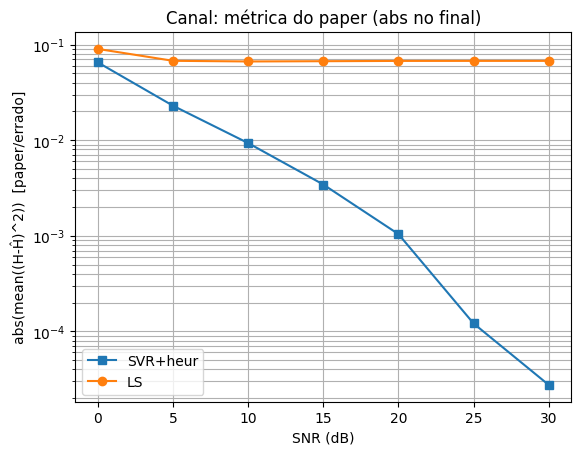

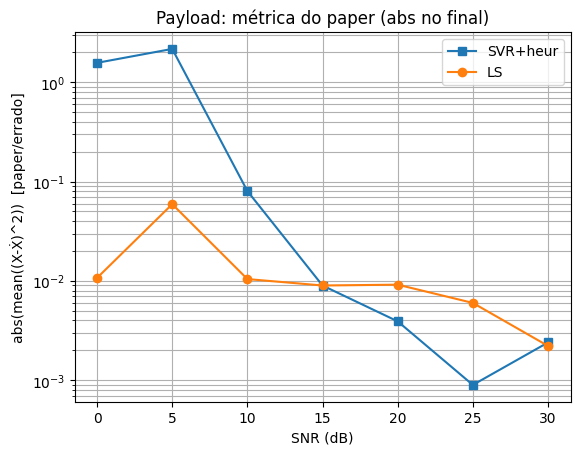

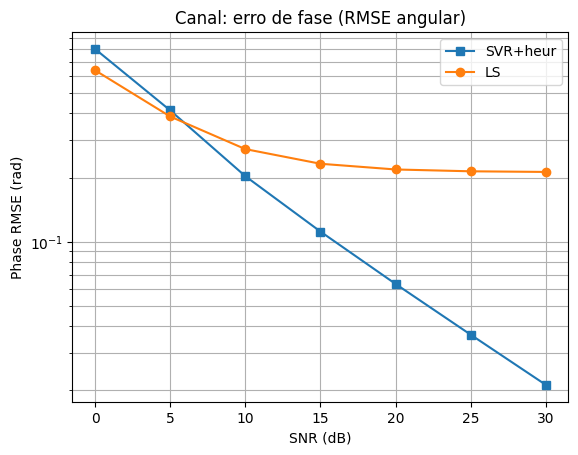

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# Configuração
# ============================================================
K = 16
P0 = 4
pilotValue = 3 + 3j
SB = 10
mu = 4
amostras = 2000  # aumente se quiser

DD = list(range(35))
D = DD[::5]  # 0,5,10,15,20,25,30 dB

# ============================================================
# Carriers / pilotos
# ============================================================
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                  # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                   # 5
dataCarriers = np.delete(allCarriers, pilotCarriers)
payloadBits_per_OFDM = len(dataCarriers) * mu

# ============================================================
# 16-QAM mapping/demapping
# ============================================================
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}
demapping_table = {v: k for k, v in mapping_table.items()}
constellation = np.array(list(demapping_table.keys()))

def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def PS(bits2d):
    return bits2d.reshape((-1,))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def Demapping(QAM):
    dists = np.abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    const_index = dists.argmin(axis=1)
    hardDecision = constellation[const_index]
    bits_hat = np.vstack([demapping_table[c] for c in hardDecision])
    return bits_hat, hardDecision

# ============================================================
# Canal verdadeiro
# ============================================================
channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# OFDM helpers
# ============================================================
def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):  return np.fft.fft(x)
def IDFT(X): return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    return symbols_1d.reshape((SB, K))  # (SB, K)

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full"
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j*np.random.randn(*convolved.shape))
    return convolved + noise

# ============================================================
# Features tempo para SVR
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2*np.pi/K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# Heurística 3 taps (paper)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2)*(1/5.7)*np.abs(H_est_t[0]) * np.exp(1j*(fase[0] - np.pi/4.5)),
        (1/4)*H_est_t[1],
        np.sqrt(2)*(1/5)*H_est_t[2] * np.exp(1j*(fase[0] - np.pi/2 + np.pi/25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    return np.fft.fft(H_est_T, K)

# ============================================================
# LS (paper): interp mag/fase
# ============================================================
def channelEstimate_LS_article(OFDM_demod):
    pilots = OFDM_demod[pilotCarriers]
    Hest_at_pilots = pilots / pilotValue

    Hest_abs = scipy.interpolate.interp1d(
        pilotCarriers, np.abs(Hest_at_pilots), kind="linear"
    )(allCarriers)

    Hest_phase = scipy.interpolate.interp1d(
        pilotCarriers, np.angle(Hest_at_pilots), kind="linear"
    )(allCarriers)

    return Hest_abs * np.exp(1j * Hest_phase)

# ============================================================
# Métricas "paper/caóticas" (abs só no final por SNR)
# ============================================================
def mse_paper_complex(a, b):
    # por amostra: COMPLEXO
    return np.mean((a - b) ** 2)

def payload_mse_paper_complex(x, xhat):
    # por amostra: COMPLEXO (não energia)
    return np.mean((x - xhat) ** 2)

# Fase: métrica angular correta (RMSE em rad)
def phase_rmse(H_true, H_est, eps=1e-12):
    mask = np.abs(H_true) > eps
    dphi = np.angle(H_true[mask] * np.conj(H_est[mask]))  # em [-pi, pi]
    return np.sqrt(np.mean(dphi**2))

# ============================================================
# Simulação
# ============================================================
mse_ch_svr = []
mse_ch_ls  = []

mse_pay_svr = []
mse_pay_ls  = []

phi_svr = []
phi_ls  = []

for SNRdb in D:
    # listas por amostra (Monte Carlo)
    ch_svr_samples = []
    ch_ls_samples  = []

    pay_svr_samples = []
    pay_ls_samples  = []

    phi_svr_samples = []
    phi_ls_samples  = []

    for _ in range(amostras):
        # --------------------------
        # Gera dados (SB símbolos)
        # --------------------------
        QAM_tx_all = []
        OFDM_tx_time = []

        for _sb in range(SB):
            bits = np.random.binomial(1, 0.5, size=(payloadBits_per_OFDM,))
            qam = Mapping(SP(bits))
            QAM_tx_all.append(qam)

            X = OFDM_symbol(qam)
            x = IDFT(X)
            OFDM_tx_time.append(x)

        qam_true = np.concatenate(QAM_tx_all)
        OFDM_tx_time = np.concatenate(OFDM_tx_time)

        # --------------------------
        # Preâmbulo (2 símbolos)
        # --------------------------
        Xp = OFDM_symbol_p()
        xp = IDFT(Xp)
        preamble = np.concatenate([xp, xp])

        # Frame completo
        tx_frame = np.concatenate([preamble, OFDM_tx_time])
        rx_frame = channel(tx_frame, SNRdb)

        # ======================================================
        # SVR estima pelo 2º símbolo do preâmbulo (K:2K)
        # ======================================================
        y2 = rx_frame[K:2*K]

        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y2.real)
        svr_im.fit(pilots_at_time_imag, y2.imag)

        H_est_time = svr_re.predict(pilots_at_time_real) + 1j*svr_im.predict(pilots_at_time_imag)
        Hest_svr = heuristic_3taps_from_time(H_est_time)

        # Dados recebidos
        rx_data = rx_frame[2*K:(2+SB)*K]
        rx_mat = SP_carrier(rx_data).T  # (K, SB)

        # ---------- Payload estimado com SVR (1 H para todos)
        qam_hat_svr_all = []
        for sb in range(SB):
            Y = DFT(rx_mat[:, sb])
            Yeq = Y / (Hest_svr + 1e-12)
            qam_hat_svr_all.append(Yeq[dataCarriers])
        qam_hat_svr = np.concatenate(qam_hat_svr_all)

        # Métricas por amostra (paper/caóticas)
        ch_svr_samples.append(mse_paper_complex(H_exact, Hest_svr))
        pay_svr_samples.append(payload_mse_paper_complex(qam_true, qam_hat_svr))
        phi_svr_samples.append(phase_rmse(H_exact, Hest_svr))

        # ======================================================
        # LS por símbolo (como no seu LS)
        # ======================================================
        ch_ls_sym = []
        phi_ls_sym = []
        qam_hat_ls_all = []

        for sb in range(SB):
            Y = DFT(rx_mat[:, sb])
            Hest_ls = channelEstimate_LS_article(Y)

            Yeq = Y / (Hest_ls + 1e-12)
            qam_hat_ls_all.append(Yeq[dataCarriers])

            ch_ls_sym.append(mse_paper_complex(H_exact, Hest_ls))
            phi_ls_sym.append(phase_rmse(H_exact, Hest_ls))

        qam_hat_ls = np.concatenate(qam_hat_ls_all)

        ch_ls_samples.append(np.mean(ch_ls_sym))  # ainda complexo
        pay_ls_samples.append(payload_mse_paper_complex(qam_true, qam_hat_ls))
        phi_ls_samples.append(np.mean(phi_ls_sym))

    # ======================================================
    # Agregação por SNR (ABS SÓ AQUI)
    # ======================================================
    mse_ch_svr.append(np.abs(np.mean(ch_svr_samples)))
    mse_ch_ls.append(np.abs(np.mean(ch_ls_samples)))

    mse_pay_svr.append(np.abs(np.mean(pay_svr_samples)))  # ✅ abs só no final (payload)
    mse_pay_ls.append(np.abs(np.mean(pay_ls_samples)))    # ✅ abs só no final (payload)

    phi_svr.append(np.mean(phi_svr_samples))
    phi_ls.append(np.mean(phi_ls_samples))

    print(f"SNR={SNRdb:>2} | CH(paper) SVR={mse_ch_svr[-1]:.3e} LS={mse_ch_ls[-1]:.3e} "
          f"| PAY(paper) SVR={mse_pay_svr[-1]:.3e} LS={mse_pay_ls[-1]:.3e} "
          f"| PHI RMSE SVR={phi_svr[-1]:.3e} LS={phi_ls[-1]:.3e}")

# ============================================================
# PLOTS
# ============================================================

# 1) Canal: métrica "paper/errada"
plt.figure()
plt.semilogy(D, mse_ch_svr, marker="s")
plt.semilogy(D, mse_ch_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("abs(mean((H-Ĥ)^2))  [paper/errado]")
plt.title("Canal: métrica do paper (abs no final)")
plt.legend(["SVR+heur", "LS"])
plt.show()

# 2) Payload: métrica "paper/errada" (o que você pediu)
plt.figure()
plt.semilogy(D, mse_pay_svr, marker="s")
plt.semilogy(D, mse_pay_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("abs(mean((X-Ẋ)^2))  [paper/errado]")
plt.title("Payload: métrica do paper (abs no final)")
plt.legend(["SVR+heur", "LS"])
plt.show()

# 3) Fase: RMSE angular (correto)
plt.figure()
plt.semilogy(D, phi_svr, marker="s")
plt.semilogy(D, phi_ls, marker="o")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("Phase RMSE (rad)")
plt.title("Canal: erro de fase (RMSE angular)")
plt.legend(["SVR+heur", "LS"])
plt.show()

SNR= 0 dB | CH-MSE SVR=8.342e-01 LS=6.965e-01 HEU=9.743e-01 | EVMn SVR=1.392e+01 LS=2.063e+00 HEU=7.900e+00 | BER SVR=3.828e-01 LS=3.550e-01 HEU=3.682e-01
SNR= 5 dB | CH-MSE SVR=2.624e-01 LS=2.562e-01 HEU=3.028e-01 | EVMn SVR=1.030e+01 LS=7.307e-01 HEU=3.774e+00 | BER SVR=2.594e-01 LS=2.426e-01 HEU=2.538e-01
SNR=10 dB | CH-MSE SVR=8.656e-02 LS=1.303e-01 HEU=1.118e-01 | EVMn SVR=6.306e-01 LS=2.893e-01 HEU=4.911e-01 | BER SVR=1.405e-01 LS=1.476e-01 HEU=1.473e-01
SNR=15 dB | CH-MSE SVR=2.987e-02 LS=9.338e-02 HEU=4.845e-02 | EVMn SVR=1.523e-01 LS=1.632e-01 HEU=1.530e-01 | BER SVR=6.020e-02 LS=9.438e-02 HEU=7.300e-02
SNR=20 dB | CH-MSE SVR=9.807e-03 LS=8.176e-02 HEU=3.038e-02 | EVMn SVR=7.231e-02 LS=1.238e-01 HEU=8.951e-02 | BER SVR=2.602e-02 LS=7.296e-02 HEU=4.060e-02
SNR=25 dB | CH-MSE SVR=3.038e-03 LS=7.781e-02 HEU=2.436e-02 | EVMn SVR=4.781e-02 LS=1.114e-01 HEU=6.965e-02 | BER SVR=1.442e-02 LS=6.494e-02 HEU=2.854e-02
SNR=30 dB | CH-MSE SVR=1.028e-03 LS=7.658e-02 HEU=2.234e-02 | EVMn SVR

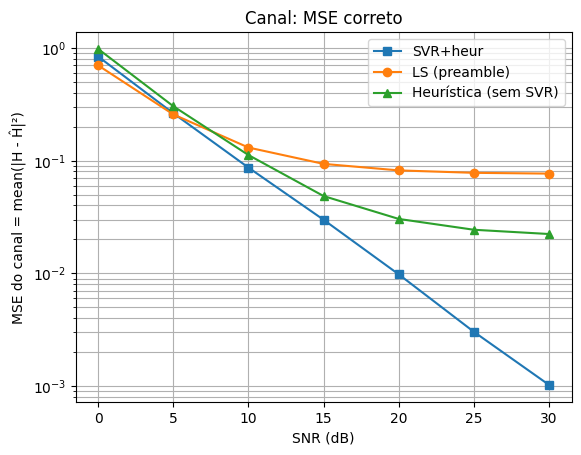

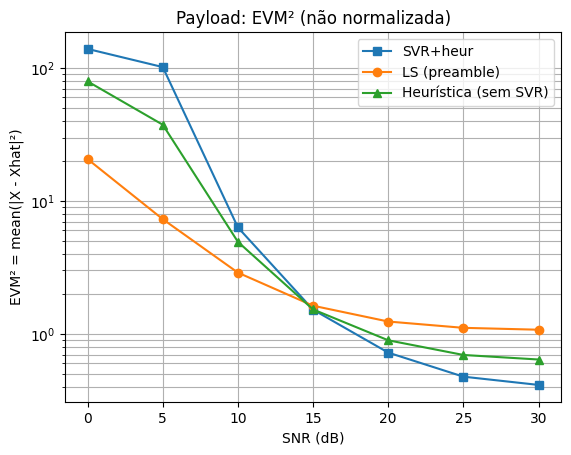

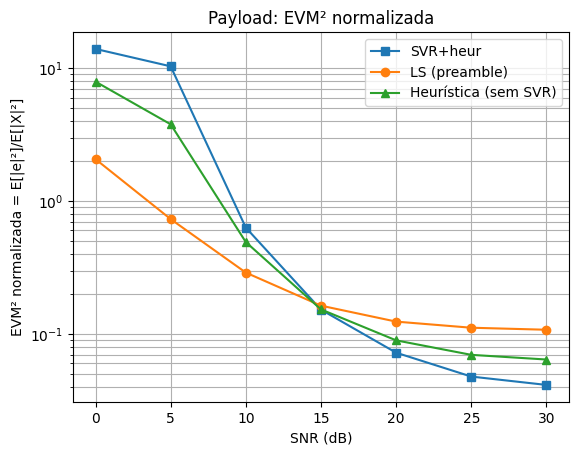

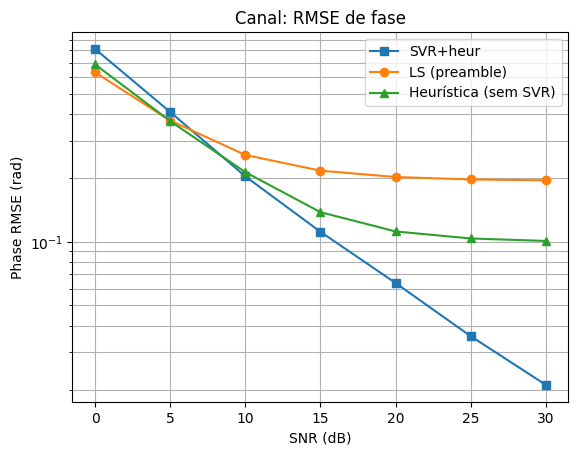

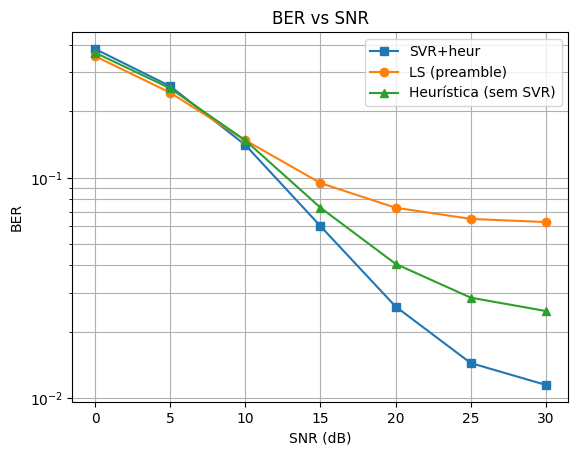

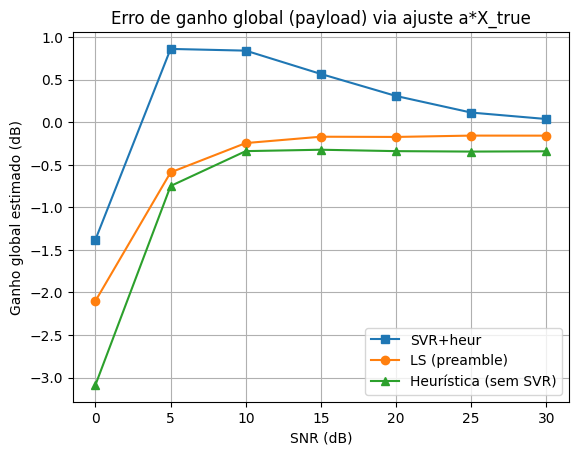

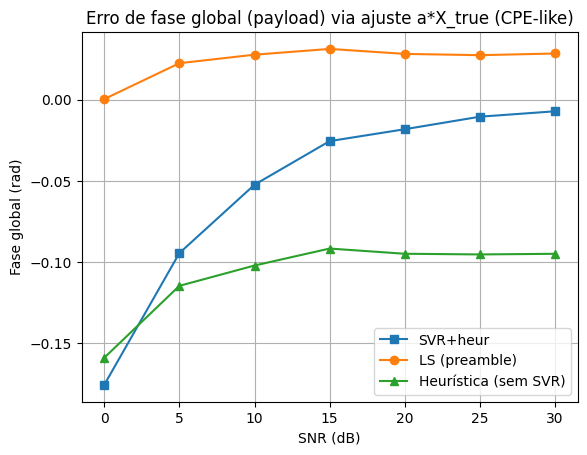

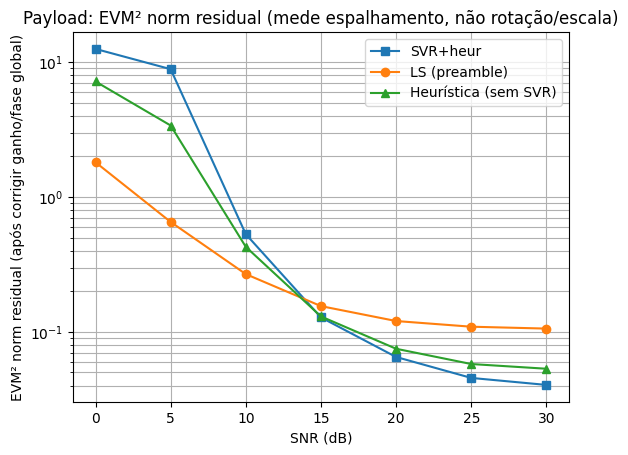

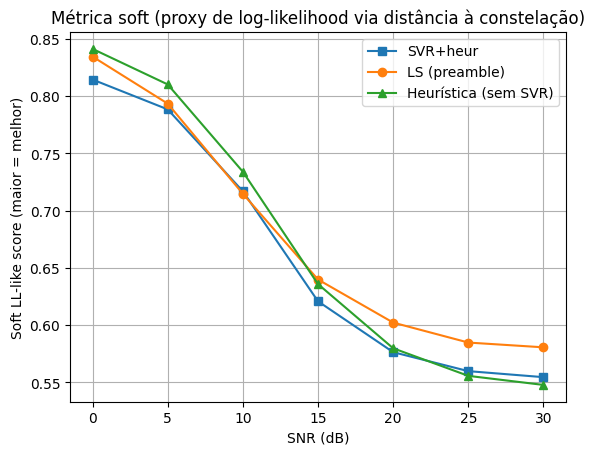

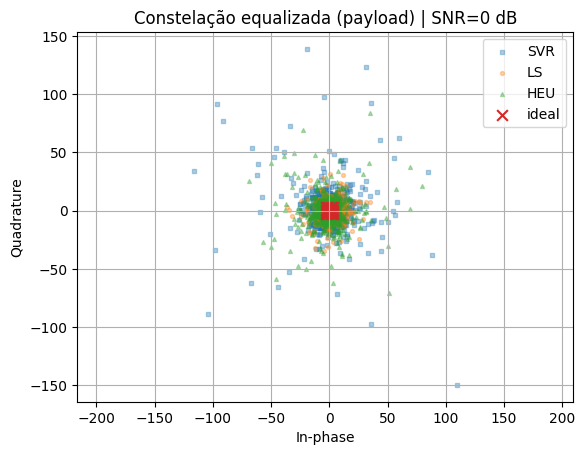

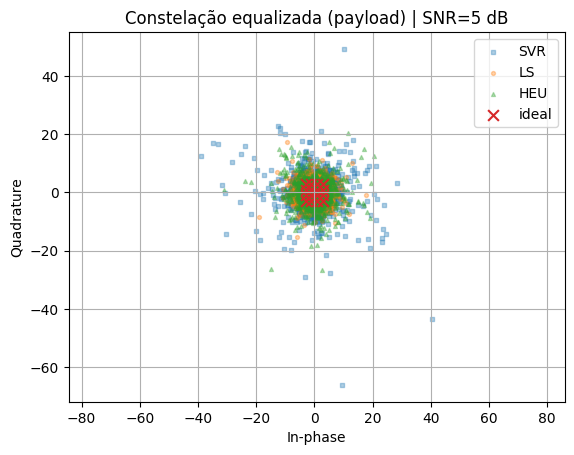

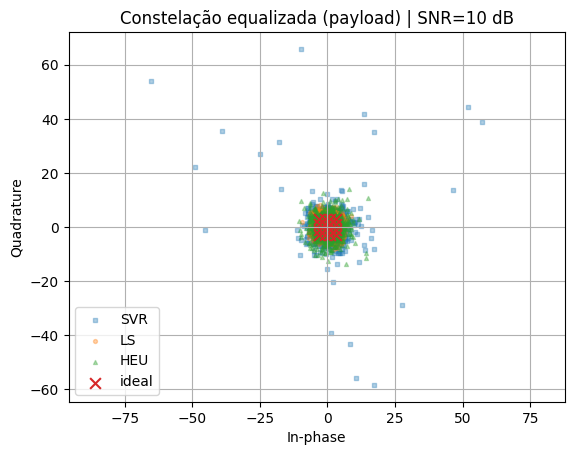

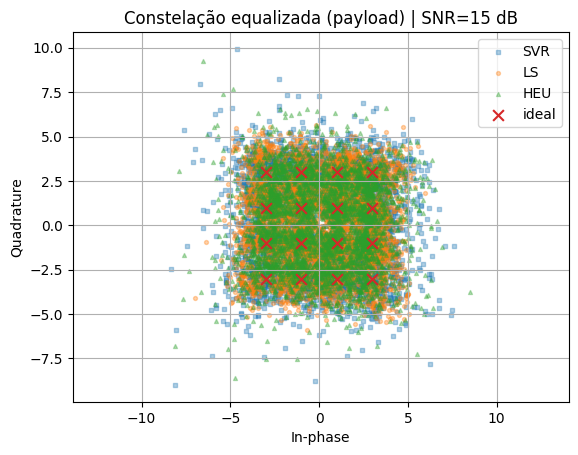

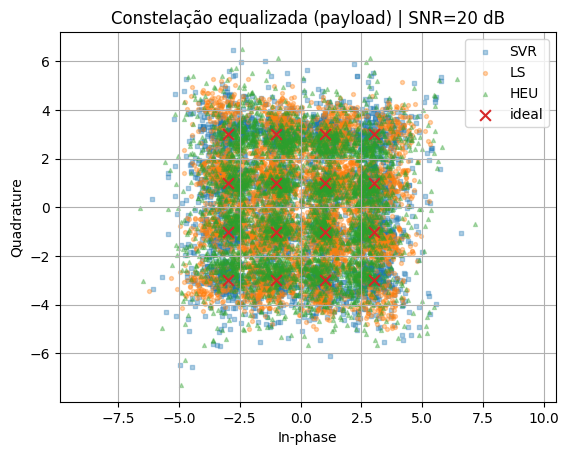

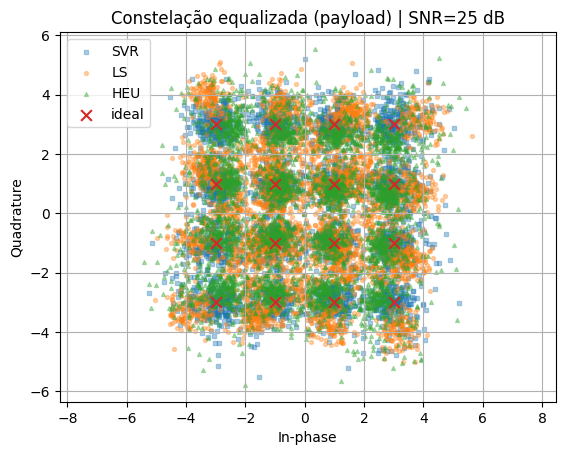

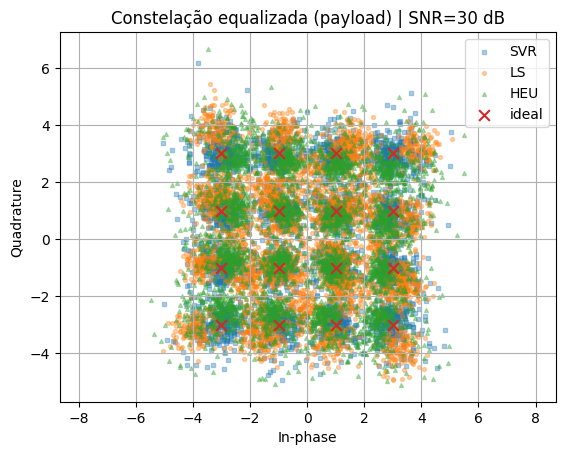

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# CONFIG
# ============================================================
K = 16
CP = 0
P0 = 4
pilotValue = 3 + 3j
SB = 10
mu = 4
amostras = 2000

DD = list(range(35))
D = DD[::5]  # 0,5,10,15,20,25,30 dB

# Para reprodutibilidade (opcional)
# np.random.seed(42)

# Para scatter de constelação (SNRs escolhidos)
SNR_SCATTER = D
scatter_max_points = 4000  # limita pontos no scatter por método/SNR

# ============================================================
# CARRIERS / PILOTOS
# ============================================================
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                  # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                   # 5
dataCarriers = np.delete(allCarriers, pilotCarriers)
payloadBits_per_OFDM = len(dataCarriers) * mu

# ============================================================
# 16-QAM mapping/demapping
# ============================================================
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}
demapping_table = {v: k for k, v in mapping_table.items()}
constellation = np.array(list(demapping_table.keys()), dtype=np.complex128)

def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def PS(bits2d):
    return bits2d.reshape((-1,))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def Demapping(QAM):
    dists = np.abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    idx = dists.argmin(axis=1)
    hardDecision = constellation[idx]
    bits_hat = np.vstack([demapping_table[c] for c in hardDecision])
    return bits_hat, hardDecision

# ============================================================
# TRUE CHANNEL
# ============================================================
channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# OFDM HELPERS
# ============================================================
def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):  return np.fft.fft(x)
def IDFT(X): return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    return symbols_1d.reshape((SB, K))  # (SB, K)

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full"
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j*np.random.randn(*convolved.shape))
    return convolved + noise

# ============================================================
# SVR FEATURES (paper-style)
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2*np.pi/K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# 3-TAP HEURISTIC (paper)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2)*(1/5.7)*np.abs(H_est_t[0]) * np.exp(1j*(fase[0] - np.pi/4.5)),
        (1/4)*H_est_t[1],
        np.sqrt(2)*(1/5)*H_est_t[2] * np.exp(1j*(fase[0] - np.pi/2 + np.pi/25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    return np.fft.fft(H_est_T, K)

# ============================================================
# LS ON PREAMBLE (FAIR COMPARISON)
#   Use FFT of known pilot-only symbol, estimate H at all carriers:
#   H_ls = Yp / Xp   (Xp known)
# ============================================================
def ls_from_preamble_time(preamble_time_symbol):
    # preamble_time_symbol: (K,) time-domain of 2nd preamble symbol received
    Yp = DFT(preamble_time_symbol)
    Xp = OFDM_symbol_p()  # frequency-domain known pilot-only symbol
    # Avoid div by 0 on non-pilot carriers: Xp is 0 there.
    # We only trust pilots and interpolate mag/phase to all carriers (same spirit as paper),
    # but now using preamble (fair).
    pilots = Yp[pilotCarriers]
    H_p = pilots / pilotValue
    H_abs = scipy.interpolate.interp1d(pilotCarriers, np.abs(H_p), kind="linear")(allCarriers)
    H_ph  = scipy.interpolate.interp1d(pilotCarriers, np.angle(H_p), kind="linear")(allCarriers)
    return H_abs * np.exp(1j * H_ph)

# ============================================================
# METRICS (ALL CORRECT NOW)
# ============================================================
def mse_channel(H_true, H_est):
    return np.mean(np.abs(H_true - H_est)**2)

def evm2_payload(X_true, X_hat):
    # EVM^2 (não normalizada)
    return np.mean(np.abs(X_true - X_hat)**2)

def evm2_payload_norm(X_true, X_hat, eps=1e-12):
    return np.mean(np.abs(X_true - X_hat)**2) / (np.mean(np.abs(X_true)**2) + eps)

def phase_rmse(H_true, H_est, eps=1e-12):
    mask = np.abs(H_true) > eps
    dphi = np.angle(H_true[mask] * np.conj(H_est[mask]))  # [-pi, pi]
    return np.sqrt(np.mean(dphi**2))

def gain_phase_error(X_true, X_hat, eps=1e-12):
    """
    Ajusta um ganho/rotação complexa global 'a' que minimiza ||X_hat - a*X_true||^2
    a = <X_hat, X_true> / <X_true, X_true>
    Retorna:
      gain_err_dB = 20log10(|a|)
      phase_err_rad = angle(a)
      resid_evm2_norm = E[|X_hat - a X_true|^2]/E[|X_true|^2]
    """
    num = np.vdot(X_true, X_hat)            # sum conj(X_true)*X_hat
    den = np.vdot(X_true, X_true) + eps
    a = num / den
    gain_err_db = 20*np.log10(np.abs(a) + eps)
    phase_err_rad = np.angle(a)
    resid = X_hat - a*X_true
    resid_evm2_norm = (np.mean(np.abs(resid)**2) / (np.mean(np.abs(X_true)**2) + eps))
    return gain_err_db, phase_err_rad, resid_evm2_norm

# Simple "log-likelihood-like" score (soft metric proxy):
# Use min-distance to constellation under AWGN (unknown sigma): score = mean(exp(-dmin^2 / s2))
# We'll estimate s2 from residual error power on payload after global gain/phase correction.
def soft_ll_score(X_true, X_hat, eps=1e-12):
    # global correction using X_true (for analysis only)
    _, _, _ = gain_phase_error(X_true, X_hat, eps=eps)
    # estimate sigma^2 from raw error (proxy)
    err = X_hat - X_true
    s2 = np.mean(np.abs(err)**2) + eps

    # compute min squared distance to constellation for each symbol
    d2 = np.abs(X_hat.reshape(-1,1) - constellation.reshape(1,-1))**2
    d2min = d2.min(axis=1)
    score = np.mean(np.exp(-d2min / s2))
    # higher is "more likely/clean"
    return score

# ============================================================
# STORAGE
# ============================================================
# Channel MSE
mse_ch_svr = []
mse_ch_ls  = []
mse_ch_heu = []

# Payload EVM^2
evm2_svr = []
evm2_ls  = []
evm2_heu = []

# Payload normalized EVM^2
evm2n_svr = []
evm2n_ls  = []
evm2n_heu = []

# Phase RMSE of channel
phi_svr = []
phi_ls  = []
phi_heu = []

# BER
ber_svr = []
ber_ls  = []
ber_heu = []

# Gain/phase error on payload (global)
gain_svr = []
gain_ls  = []
gain_heu = []
cpe_svr = []
cpe_ls  = []
cpe_heu = []
resid_evm2n_svr = []
resid_evm2n_ls  = []
resid_evm2n_heu = []

# Soft "LL" score
ll_svr = []
ll_ls  = []
ll_heu = []

# Constellation buffers
scatter_buf = {
    "SVR": {snr: [] for snr in SNR_SCATTER},
    "LS":  {snr: [] for snr in SNR_SCATTER},
    "HEU": {snr: [] for snr in SNR_SCATTER},
}

# ============================================================
# MAIN SIM
# ============================================================
for SNRdb in D:
    # per-SNR accumulators
    ch_svr_s = []; ch_ls_s = []; ch_heu_s = []
    evm_svr_s = []; evm_ls_s = []; evm_heu_s = []
    evmn_svr_s = []; evmn_ls_s = []; evmn_heu_s = []
    phi_svr_s = []; phi_ls_s = []; phi_heu_s = []
    ber_svr_s = []; ber_ls_s = []; ber_heu_s = []
    gain_svr_s = []; gain_ls_s = []; gain_heu_s = []
    cpe_svr_s = []; cpe_ls_s = []; cpe_heu_s = []
    resid_svr_s = []; resid_ls_s = []; resid_heu_s = []
    ll_svr_s = []; ll_ls_s = []; ll_heu_s = []

    for _ in range(amostras):
        # --------------------------
        # TX: generate SB OFDM data symbols
        # --------------------------
        bits_tx_all = []
        QAM_tx_all = []      # per symbol payload
        OFDM_tx_time = []

        for _sb in range(SB):
            bits = np.random.binomial(1, 0.5, size=(payloadBits_per_OFDM,))
            bits_tx_all.append(bits)

            qam = Mapping(SP(bits))
            QAM_tx_all.append(qam)

            X = OFDM_symbol(qam)
            x = IDFT(X)
            OFDM_tx_time.append(x)

        bits_tx_all = np.concatenate(bits_tx_all)
        qam_true = np.concatenate(QAM_tx_all)  # payload truth across all SB symbols
        OFDM_tx_time = np.concatenate(OFDM_tx_time)

        # --------------------------
        # Preamble (2 pilot-only symbols)
        # --------------------------
        Xp = OFDM_symbol_p()
        xp = IDFT(Xp)
        preamble = np.concatenate([xp, xp])

        # Full frame through channel
        tx_frame = np.concatenate([preamble, OFDM_tx_time])
        rx_frame = channel(tx_frame, SNRdb)

        # Receive 2nd preamble symbol in time
        y2 = rx_frame[K:2*K]

        # ======================================================
        # (A) SVR estimate from SAME PREAMBLE
        # ======================================================
        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y2.real)
        svr_im.fit(pilots_at_time_imag, y2.imag)

        H_est_time_svr = svr_re.predict(pilots_at_time_real) + 1j*svr_im.predict(pilots_at_time_imag)
        Hest_svr = heuristic_3taps_from_time(H_est_time_svr)

        # ======================================================
        # (B) HEUR only (no SVR): apply heuristic directly to y2
        # ======================================================
        Hest_heu = heuristic_3taps_from_time(y2)

        # ======================================================
        # (C) LS estimate from SAME PREAMBLE (fair)
        # ======================================================
        Hest_ls = ls_from_preamble_time(y2)

        # ======================================================
        # RX DATA (SB symbols)
        # ======================================================
        rx_data = rx_frame[2*K:(2+SB)*K]
        rx_mat = SP_carrier(rx_data).T  # (K, SB)

        # Helper: equalize all SB symbols with a fixed Hest (one per method)
        def equalize_payload(Hest):
            qam_hat_all = []
            bits_hat_all = []
            for sb in range(SB):
                Y = DFT(rx_mat[:, sb])
                Yeq = Y / (Hest + 1e-12)
                qam_hat = Yeq[dataCarriers]
                qam_hat_all.append(qam_hat)

                b2d, _ = Demapping(qam_hat)
                bits_hat_all.append(PS(b2d))
            return np.concatenate(qam_hat_all), np.concatenate(bits_hat_all)

        qam_hat_svr, bits_hat_svr = equalize_payload(Hest_svr)
        qam_hat_ls,  bits_hat_ls  = equalize_payload(Hest_ls)
        qam_hat_heu, bits_hat_heu = equalize_payload(Hest_heu)

        # ======================================================
        # METRICS: Channel
        # ======================================================
        ch_svr_s.append(mse_channel(H_exact, Hest_svr))
        ch_ls_s.append(mse_channel(H_exact, Hest_ls))
        ch_heu_s.append(mse_channel(H_exact, Hest_heu))

        phi_svr_s.append(phase_rmse(H_exact, Hest_svr))
        phi_ls_s.append(phase_rmse(H_exact, Hest_ls))
        phi_heu_s.append(phase_rmse(H_exact, Hest_heu))

        # ======================================================
        # METRICS: Payload EVM/BER
        # ======================================================
        evm_svr_s.append(evm2_payload(qam_true, qam_hat_svr))
        evm_ls_s.append(evm2_payload(qam_true, qam_hat_ls))
        evm_heu_s.append(evm2_payload(qam_true, qam_hat_heu))

        evmn_svr_s.append(evm2_payload_norm(qam_true, qam_hat_svr))
        evmn_ls_s.append(evm2_payload_norm(qam_true, qam_hat_ls))
        evmn_heu_s.append(evm2_payload_norm(qam_true, qam_hat_heu))

        ber_svr_s.append(np.mean(bits_tx_all != bits_hat_svr))
        ber_ls_s.append(np.mean(bits_tx_all != bits_hat_ls))
        ber_heu_s.append(np.mean(bits_tx_all != bits_hat_heu))

        # Global gain/phase error analysis (payload)
        g_db, ph, resid = gain_phase_error(qam_true, qam_hat_svr)
        gain_svr_s.append(g_db); cpe_svr_s.append(ph); resid_svr_s.append(resid)

        g_db, ph, resid = gain_phase_error(qam_true, qam_hat_ls)
        gain_ls_s.append(g_db); cpe_ls_s.append(ph); resid_ls_s.append(resid)

        g_db, ph, resid = gain_phase_error(qam_true, qam_hat_heu)
        gain_heu_s.append(g_db); cpe_heu_s.append(ph); resid_heu_s.append(resid)

        # Soft LL-like score
        ll_svr_s.append(soft_ll_score(qam_true, qam_hat_svr))
        ll_ls_s.append(soft_ll_score(qam_true, qam_hat_ls))
        ll_heu_s.append(soft_ll_score(qam_true, qam_hat_heu))

        # Constellation buffer
        if SNRdb in SNR_SCATTER:
            # append up to scatter_max_points
            for name, arr in [("SVR", qam_hat_svr), ("LS", qam_hat_ls), ("HEU", qam_hat_heu)]:
                buf = scatter_buf[name][SNRdb]
                if len(buf) < scatter_max_points:
                    need = scatter_max_points - len(buf)
                    buf.extend(list(arr[:need]))

    # Aggregate per SNR
    mse_ch_svr.append(np.mean(ch_svr_s))
    mse_ch_ls.append(np.mean(ch_ls_s))
    mse_ch_heu.append(np.mean(ch_heu_s))

    evm2_svr.append(np.mean(evm_svr_s))
    evm2_ls.append(np.mean(evm_ls_s))
    evm2_heu.append(np.mean(evm_heu_s))

    evm2n_svr.append(np.mean(evmn_svr_s))
    evm2n_ls.append(np.mean(evmn_ls_s))
    evm2n_heu.append(np.mean(evmn_heu_s))

    phi_svr.append(np.mean(phi_svr_s))
    phi_ls.append(np.mean(phi_ls_s))
    phi_heu.append(np.mean(phi_heu_s))

    ber_svr.append(np.mean(ber_svr_s))
    ber_ls.append(np.mean(ber_ls_s))
    ber_heu.append(np.mean(ber_heu_s))

    gain_svr.append(np.mean(gain_svr_s))
    gain_ls.append(np.mean(gain_ls_s))
    gain_heu.append(np.mean(gain_heu_s))

    cpe_svr.append(np.mean(cpe_svr_s))
    cpe_ls.append(np.mean(cpe_ls_s))
    cpe_heu.append(np.mean(cpe_heu_s))

    resid_evm2n_svr.append(np.mean(resid_svr_s))
    resid_evm2n_ls.append(np.mean(resid_ls_s))
    resid_evm2n_heu.append(np.mean(resid_heu_s))

    ll_svr.append(np.mean(ll_svr_s))
    ll_ls.append(np.mean(ll_ls_s))
    ll_heu.append(np.mean(ll_heu_s))

    print(
        f"SNR={SNRdb:>2} dB | CH-MSE SVR={mse_ch_svr[-1]:.3e} LS={mse_ch_ls[-1]:.3e} HEU={mse_ch_heu[-1]:.3e} "
        f"| EVMn SVR={evm2n_svr[-1]:.3e} LS={evm2n_ls[-1]:.3e} HEU={evm2n_heu[-1]:.3e} "
        f"| BER SVR={ber_svr[-1]:.3e} LS={ber_ls[-1]:.3e} HEU={ber_heu[-1]:.3e}"
    )

# ============================================================
# PLOTS (3 METHODS)
# ============================================================

# 1) Channel MSE (correct)
plt.figure()
plt.semilogy(D, mse_ch_svr, marker="s")
plt.semilogy(D, mse_ch_ls, marker="o")
plt.semilogy(D, mse_ch_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("MSE do canal = mean(|H - Ĥ|²)")
plt.title("Canal: MSE correto")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 2) Payload EVM^2 (correct, unnormalized)
plt.figure()
plt.semilogy(D, evm2_svr, marker="s")
plt.semilogy(D, evm2_ls, marker="o")
plt.semilogy(D, evm2_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("EVM² = mean(|X - Xhat|²)")
plt.title("Payload: EVM² (não normalizada)")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 3) Payload normalized EVM^2 (recommended)
plt.figure()
plt.semilogy(D, evm2n_svr, marker="s")
plt.semilogy(D, evm2n_ls, marker="o")
plt.semilogy(D, evm2n_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("EVM² normalizada = E[|e|²]/E[|X|²]")
plt.title("Payload: EVM² normalizada")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 4) Phase RMSE of channel
plt.figure()
plt.semilogy(D, phi_svr, marker="s")
plt.semilogy(D, phi_ls, marker="o")
plt.semilogy(D, phi_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("Phase RMSE (rad)")
plt.title("Canal: RMSE de fase")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 5) BER
plt.figure()
plt.semilogy(D, ber_svr, marker="s")
plt.semilogy(D, ber_ls, marker="o")
plt.semilogy(D, ber_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.title("BER vs SNR")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 6) Gain error (dB) and CPE (phase) on payload
plt.figure()
plt.plot(D, gain_svr, marker="s")
plt.plot(D, gain_ls, marker="o")
plt.plot(D, gain_heu, marker="^")
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Ganho global estimado (dB)")
plt.title("Erro de ganho global (payload) via ajuste a*X_true")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

plt.figure()
plt.plot(D, cpe_svr, marker="s")
plt.plot(D, cpe_ls, marker="o")
plt.plot(D, cpe_heu, marker="^")
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Fase global (rad)")
plt.title("Erro de fase global (payload) via ajuste a*X_true (CPE-like)")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 7) Residual EVM^2 norm after removing global gain/phase
plt.figure()
plt.semilogy(D, resid_evm2n_svr, marker="s")
plt.semilogy(D, resid_evm2n_ls, marker="o")
plt.semilogy(D, resid_evm2n_heu, marker="^")
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("EVM² norm residual (após corrigir ganho/fase global)")
plt.title("Payload: EVM² norm residual (mede espalhamento, não rotação/escala)")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# 8) Log-likelihood-like soft score
plt.figure()
plt.plot(D, ll_svr, marker="s")
plt.plot(D, ll_ls, marker="o")
plt.plot(D, ll_heu, marker="^")
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Soft LL-like score (maior = melhor)")
plt.title("Métrica soft (proxy de log-likelihood via distância à constelação)")
plt.legend(["SVR+heur", "LS (preamble)", "Heurística (sem SVR)"])
plt.show()

# ============================================================
# CONSTELLATION SCATTERS (equalized payload)
# ============================================================
# Plota constelação equalizada para SNR=0,5,10 e métodos SVR/LS/HEU
for snr in SNR_SCATTER:
    plt.figure()
    for name, marker in [("SVR", "s"), ("LS", "o"), ("HEU", "^")]:
        pts = np.array(scatter_buf[name][snr], dtype=np.complex128)
        if pts.size == 0:
            continue
        plt.scatter(pts.real, pts.imag, s=8, marker=marker, alpha=0.35, label=name)
    # constelação ideal (referência)
    plt.scatter(constellation.real, constellation.imag, s=60, marker="x", label="ideal")
    plt.grid(True)
    plt.axis("equal")
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(f"Constelação equalizada (payload) | SNR={snr} dB")
    plt.legend()
    plt.show()

SNR= 0 dB | CH-MSE: SVR+heur=1.39e+00  LS=8.36e-01  HEU=1.67e+00  SVR+LS=6.61e-01 | EVMn: SVR+heur=2.72e+01  LS=2.45e+00  HEU=1.25e+01  SVR+LS=3.57e+00 | BER: SVR+heur=5.09e-01  LS=4.49e-01  HEU=5.05e-01  SVR+LS=4.53e-01
SNR= 5 dB | CH-MSE: SVR+heur=1.09e+00  LS=5.47e-01  HEU=1.29e+00  SVR+LS=4.51e-01 | EVMn: SVR+heur=2.30e+01  LS=1.43e+00  HEU=1.10e+01  SVR+LS=2.10e+00 | BER: SVR+heur=5.16e-01  LS=4.09e-01  HEU=5.07e-01  SVR+LS=4.13e-01
SNR=10 dB | CH-MSE: SVR+heur=1.00e+00  LS=4.22e-01  HEU=1.19e+00  SVR+LS=3.59e-01 | EVMn: SVR+heur=1.73e+01  LS=1.02e+00  HEU=1.37e+01  SVR+LS=1.38e+00 | BER: SVR+heur=5.24e-01  LS=3.75e-01  HEU=5.00e-01  SVR+LS=3.72e-01
SNR=15 dB | CH-MSE: SVR+heur=9.82e-01  LS=3.72e-01  HEU=1.16e+00  SVR+LS=3.21e-01 | EVMn: SVR+heur=2.96e+01  LS=8.79e-01  HEU=4.27e+00  SVR+LS=1.11e+00 | BER: SVR+heur=5.32e-01  LS=3.58e-01  HEU=4.91e-01  SVR+LS=3.49e-01
SNR=20 dB | CH-MSE: SVR+heur=9.79e-01  LS=3.64e-01  HEU=1.15e+00  SVR+LS=3.15e-01 | EVMn: SVR+heur=3.65e+01  LS=8.43

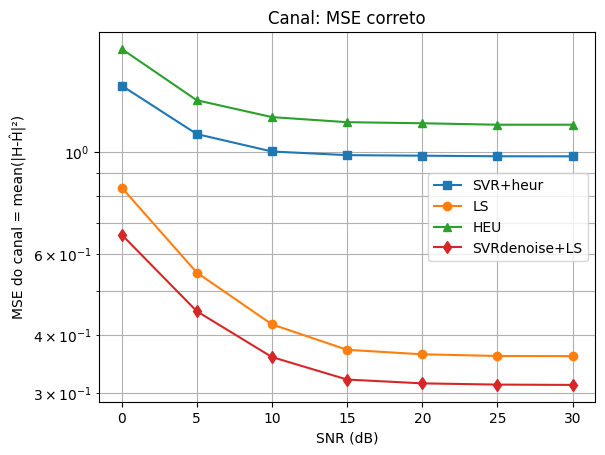

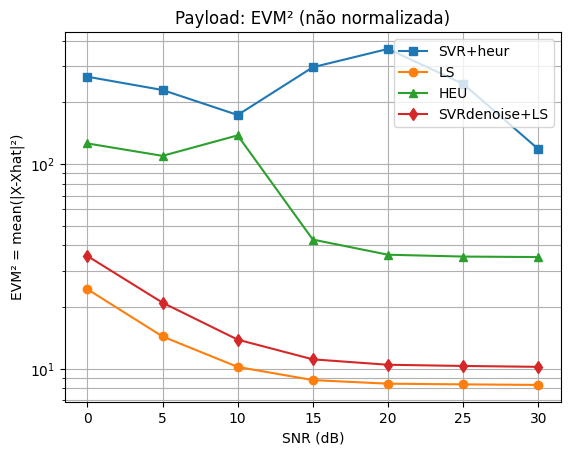

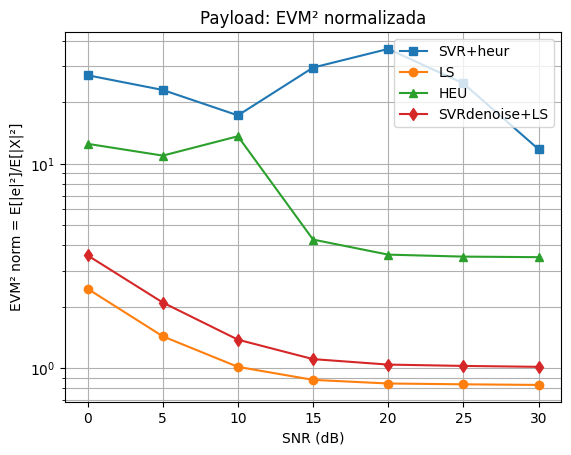

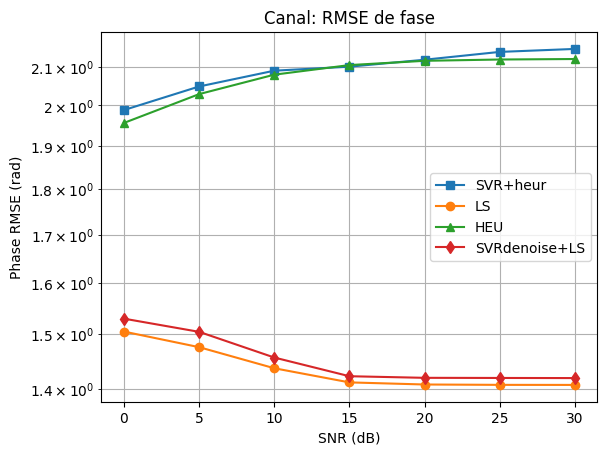

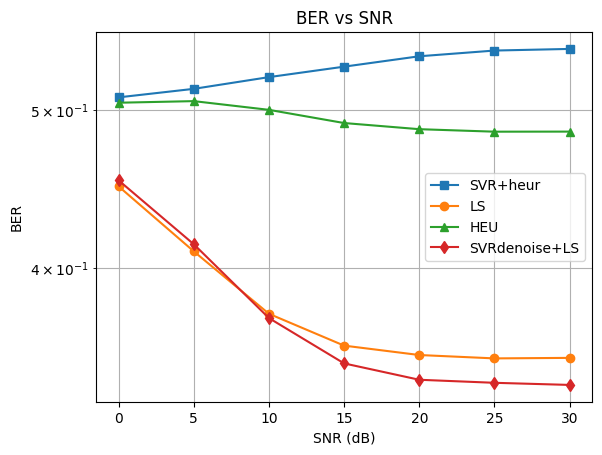

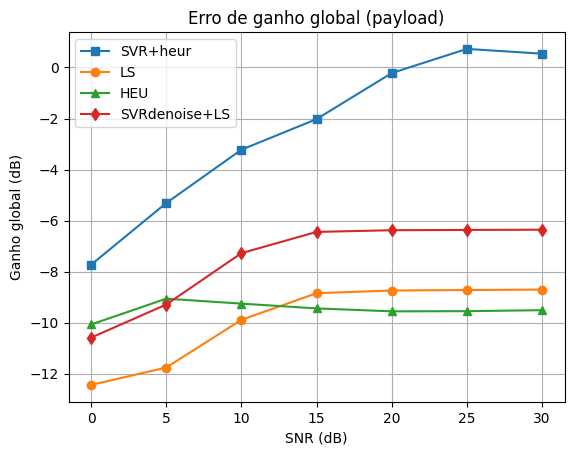

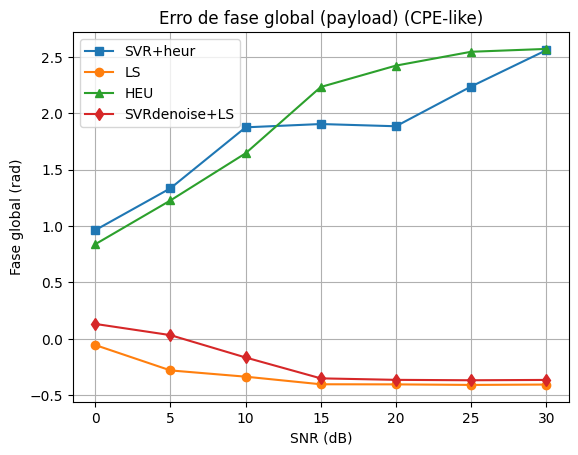

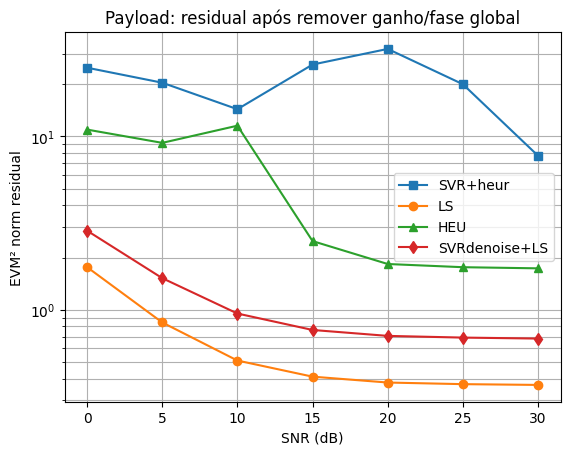

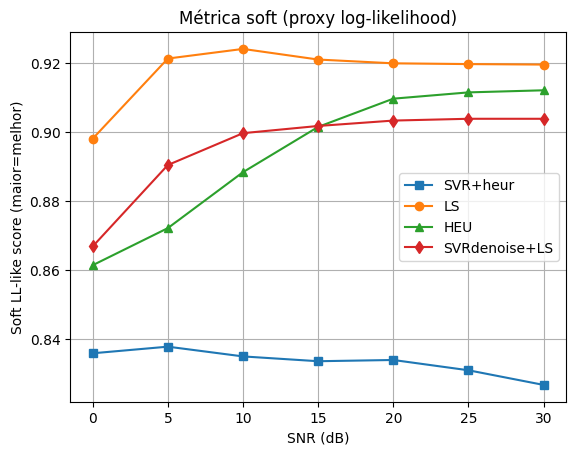

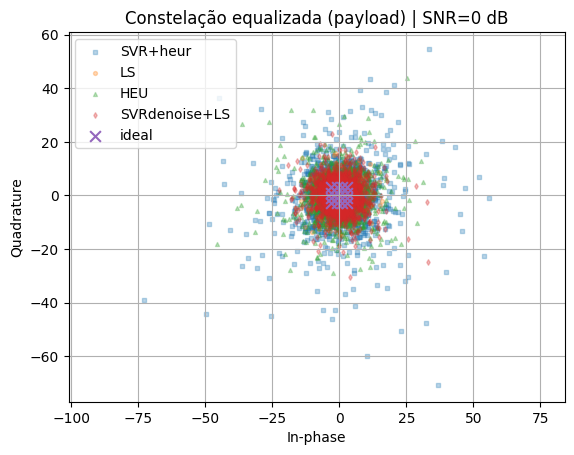

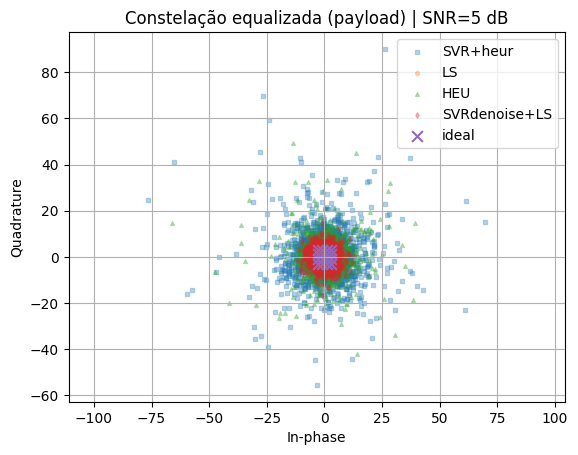

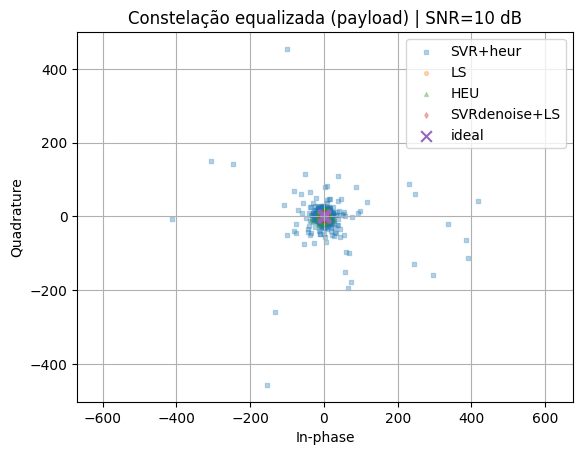

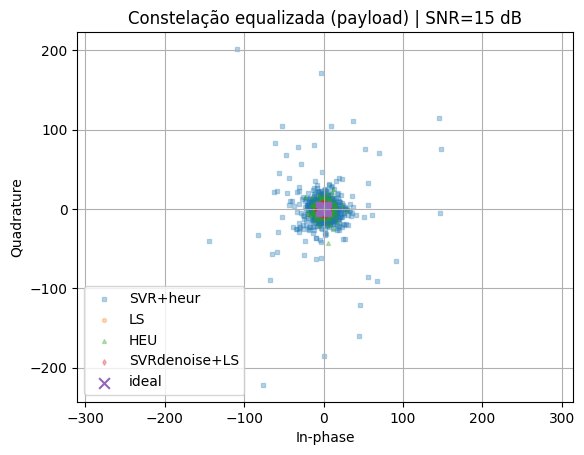

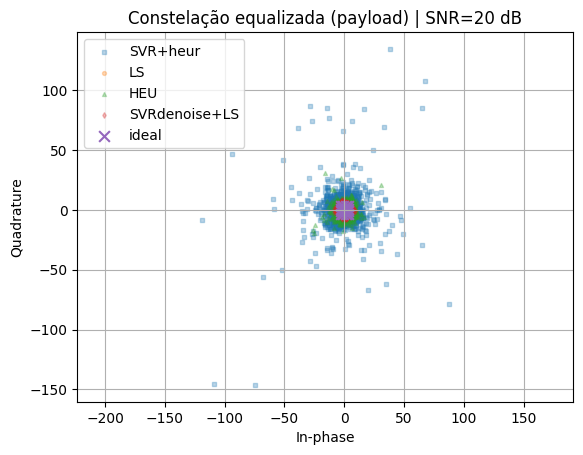

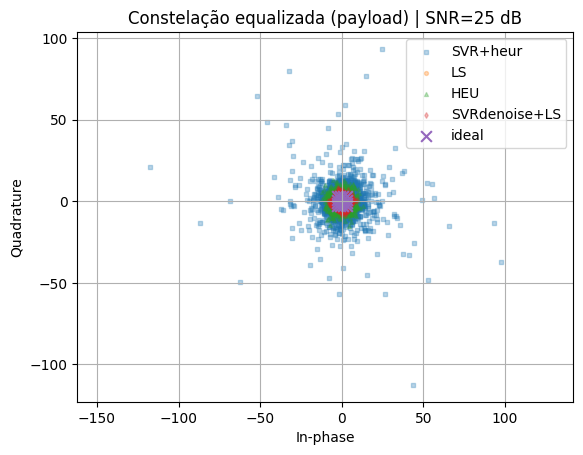

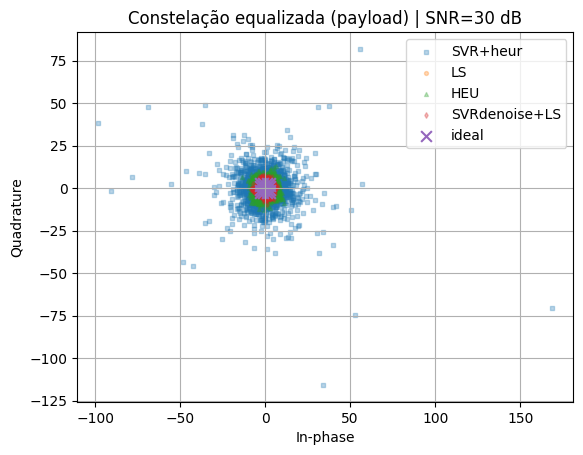

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# CONFIG
# ============================================================
K = 16
CP = 0
P0 = 4
pilotValue = 3 + 3j
SB = 10
mu = 4
amostras = 2000


DD = list(range(35))
D = DD[::5]  # 0,5,10,15,20,25,30 dB

# Para reprodutibilidade (opcional)
# np.random.seed(42)

# Para scatter de constelação (SNRs escolhidos)
SNR_SCATTER = D
scatter_max_points = 4000  # limita pontos no scatter por método/SNR

# ============================================================
# CARRIERS / PILOTOS
# ============================================================
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]                  # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15
P = len(pilotCarriers)                                   # 5
dataCarriers = np.delete(allCarriers, pilotCarriers)
payloadBits_per_OFDM = len(dataCarriers) * mu

# ============================================================
# 16-QAM mapping/demapping
# ============================================================
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}
demapping_table = {v: k for k, v in mapping_table.items()}
constellation = np.array(list(demapping_table.keys()), dtype=np.complex128)

def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def PS(bits2d):
    return bits2d.reshape((-1,))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def Demapping(QAM):
    dists = np.abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    idx = dists.argmin(axis=1)
    hardDecision = constellation[idx]
    bits_hat = np.vstack([demapping_table[c] for c in hardDecision])
    return bits_hat, hardDecision

# ============================================================
# TRUE CHANNEL
# ============================================================
#L = 3                  # número de taps do canal (comprimento no tempo)

powers_db = np.array([0, -2.2, -4, -6, -8.2, -9.9, -10.5, -7.5])
powers_linear = 10**(powers_db/10)
powers_linear /= np.sum(powers_linear)

L = len(powers_linear)

channelResponse = (
    np.random.randn(L) + 1j*np.random.randn(L)
) * np.sqrt(powers_linear/2)

#channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(channelResponse, K)

# ============================================================
# OFDM HELPERS
# ============================================================
def OFDM_symbol(QAM_payload):
    symbol = np.zeros(K, dtype=np.complex128)
    symbol[pilotCarriers] = pilotValue
    symbol[dataCarriers] = QAM_payload
    return symbol

def OFDM_symbol_p():
    symbol_p = np.zeros(K, dtype=np.complex128)
    symbol_p[pilotCarriers] = pilotValue
    return symbol_p

def DFT(x):  return np.fft.fft(x)
def IDFT(X): return np.fft.ifft(X)

def SP_carrier(symbols_1d):
    return symbols_1d.reshape((SB, K))  # (SB, K)

def channel(signal, SNRdb):
    convolved = np.convolve(signal, channelResponse)  # "full"
    signal_power = np.mean(np.abs(convolved) ** 2)
    sigma2 = signal_power * 10 ** (-SNRdb / 10)
    noise = np.sqrt(sigma2 / 2) * (np.random.randn(*convolved.shape) + 1j*np.random.randn(*convolved.shape))
    return convolved + noise

# ============================================================
# SVR FEATURES (paper-style)
# ============================================================
def build_pilots_at_time_real_imag():
    Xre = np.zeros((K, P), dtype=np.float64)
    Xim = np.zeros((K, P), dtype=np.float64)
    for j in range(P):
        basis = pilotValue * np.exp(1j * 2*np.pi/K * pilotCarriers[j] * allCarriers)
        Xre[:, j] = basis.real
        Xim[:, j] = basis.imag
    return Xre, Xim

pilots_at_time_real, pilots_at_time_imag = build_pilots_at_time_real_imag()

# ============================================================
# 3-TAP HEURISTIC (paper)
# ============================================================
def heuristic_3taps_from_time(H_est_time):
    H_est = np.array(H_est_time, dtype=np.complex128)

    H_est_t = (
        H_est[np.arange(0, 3)] +
        H_est[np.arange(4, 7)] +
        H_est[np.arange(8, 11)] +
        H_est[np.arange(12, 15)]
    )

    fase = np.arctan2(H_est_t.imag, H_est_t.real)

    H_est_T1 = [
        np.sqrt(2)*(1/5.7)*np.abs(H_est_t[0]) * np.exp(1j*(fase[0] - np.pi/4.5)),
        (1/4)*H_est_t[1],
        np.sqrt(2)*(1/5)*H_est_t[2] * np.exp(1j*(fase[0] - np.pi/2 + np.pi/25)),
    ]

    c = H_est_T1[1]
    H_est_T = np.array(H_est_T1, dtype=np.complex128) - c
    return np.fft.fft(H_est_T, K)

# ============================================================
# LS ON PREAMBLE (FAIR)
# ============================================================
def ls_from_preamble_time(preamble_time_symbol):
    Yp = DFT(preamble_time_symbol)
    pilots = Yp[pilotCarriers]
    H_p = pilots / pilotValue
    H_abs = scipy.interpolate.interp1d(pilotCarriers, np.abs(H_p), kind="linear")(allCarriers)
    H_ph  = scipy.interpolate.interp1d(pilotCarriers, np.angle(H_p), kind="linear")(allCarriers)
    return H_abs * np.exp(1j * H_ph)

# ============================================================
# METRICS (CORRECT)
# ============================================================
def mse_channel(H_true, H_est):
    return np.mean(np.abs(H_true - H_est)**2)

def evm2_payload(X_true, X_hat):
    return np.mean(np.abs(X_true - X_hat)**2)

def evm2_payload_norm(X_true, X_hat, eps=1e-12):
    return np.mean(np.abs(X_true - X_hat)**2) / (np.mean(np.abs(X_true)**2) + eps)

def phase_rmse(H_true, H_est, eps=1e-12):
    mask = np.abs(H_true) > eps
    dphi = np.angle(H_true[mask] * np.conj(H_est[mask]))  # [-pi, pi]
    return np.sqrt(np.mean(dphi**2))

def gain_phase_error(X_true, X_hat, eps=1e-12):
    num = np.vdot(X_true, X_hat)
    den = np.vdot(X_true, X_true) + eps
    a = num / den
    gain_err_db = 20*np.log10(np.abs(a) + eps)
    phase_err_rad = np.angle(a)
    resid = X_hat - a*X_true
    resid_evm2_norm = (np.mean(np.abs(resid)**2) / (np.mean(np.abs(X_true)**2) + eps))
    return gain_err_db, phase_err_rad, resid_evm2_norm

def soft_ll_score(X_true, X_hat, eps=1e-12):
    # proxy: mais alto = mais pontos "bem dentro" da constelação
    err = X_hat - X_true
    s2 = np.mean(np.abs(err)**2) + eps
    d2 = np.abs(X_hat.reshape(-1,1) - constellation.reshape(1,-1))**2
    d2min = d2.min(axis=1)
    return np.mean(np.exp(-d2min / s2))

# ============================================================
# STORAGE (4 METHODS)
# ============================================================
methods = ["SVR+heur", "LS", "HEU", "SVRdenoise+LS"]

mse_ch = {m: [] for m in methods}
evm2   = {m: [] for m in methods}
evm2n  = {m: [] for m in methods}
phi    = {m: [] for m in methods}
ber    = {m: [] for m in methods}
gain_db= {m: [] for m in methods}
cpe    = {m: [] for m in methods}
residn = {m: [] for m in methods}
ll     = {m: [] for m in methods}

scatter_buf = {m: {snr: [] for snr in SNR_SCATTER} for m in methods}

# ============================================================
# MAIN SIM
# ============================================================
for SNRdb in D:
    acc = {m: {
        "mse_ch": [], "evm2": [], "evm2n": [], "phi": [], "ber": [],
        "gain": [], "cpe": [], "resid": [], "ll": []
    } for m in methods}

    for _ in range(amostras):
        # --------------------------
        # TX
        # --------------------------
        bits_tx_all = []
        QAM_tx_all = []
        OFDM_tx_time = []

        for _sb in range(SB):
            bits = np.random.binomial(1, 0.5, size=(payloadBits_per_OFDM,))
            bits_tx_all.append(bits)

            qam = Mapping(SP(bits))
            QAM_tx_all.append(qam)

            X = OFDM_symbol(qam)
            x = IDFT(X)
            OFDM_tx_time.append(x)

        bits_tx_all = np.concatenate(bits_tx_all)
        qam_true = np.concatenate(QAM_tx_all)
        OFDM_tx_time = np.concatenate(OFDM_tx_time)

        # --------------------------
        # PREAMBLE
        # --------------------------
        Xp = OFDM_symbol_p()
        xp = IDFT(Xp)
        preamble = np.concatenate([xp, xp])

        tx_frame = np.concatenate([preamble, OFDM_tx_time])
        rx_frame = channel(tx_frame, SNRdb)

        y2 = rx_frame[K:2*K]  # 2º preâmbulo no tempo

        # ======================================================
        # (A) SVR "denoise" no TEMPO
        # ======================================================
        svr_re = SVR(kernel="rbf", C=100, gamma="auto")
        svr_im = SVR(kernel="rbf", C=100, gamma="auto")
        svr_re.fit(pilots_at_time_real, y2.real)
        svr_im.fit(pilots_at_time_imag, y2.imag)

        y2_denoised = (
            svr_re.predict(pilots_at_time_real) +
            1j*svr_im.predict(pilots_at_time_imag)
        )  # (K,) complexo

        # ======================================================
        # Estimadores de CANAL (todos usando o MESMO preâmbulo)
        # ======================================================
        H_svrheur = heuristic_3taps_from_time(y2_denoised)  # SVR + heurística
        H_heu     = heuristic_3taps_from_time(y2)           # só heurística (sem SVR)
        H_ls      = ls_from_preamble_time(y2)               # LS no preâmbulo bruto
        H_svr_ls  = ls_from_preamble_time(y2_denoised)      # ✅ LS buffado (SVR-denoise + LS)

        H_by_method = {
            "SVR+heur": H_svrheur,
            "HEU": H_heu,
            "LS": H_ls,
            "SVRdenoise+LS": H_svr_ls
        }

        # ======================================================
        # RX DATA
        # ======================================================
        rx_data = rx_frame[2*K:(2+SB)*K]
        rx_mat = SP_carrier(rx_data).T  # (K, SB)

        def equalize_payload(Hest):
            qam_hat_all = []
            bits_hat_all = []
            for sb_i in range(SB):
                Y = DFT(rx_mat[:, sb_i])
                Yeq = Y / (Hest + 1e-12)
                qam_hat = Yeq[dataCarriers]
                qam_hat_all.append(qam_hat)

                b2d, _ = Demapping(qam_hat)
                bits_hat_all.append(PS(b2d))
            return np.concatenate(qam_hat_all), np.concatenate(bits_hat_all)

        # ======================================================
        # METRICS PER METHOD
        # ======================================================
        for m in methods:
            Hest = H_by_method[m]
            qam_hat, bits_hat = equalize_payload(Hest)

            acc[m]["mse_ch"].append(mse_channel(H_exact, Hest))
            acc[m]["phi"].append(phase_rmse(H_exact, Hest))

            acc[m]["evm2"].append(evm2_payload(qam_true, qam_hat))
            acc[m]["evm2n"].append(evm2_payload_norm(qam_true, qam_hat))

            acc[m]["ber"].append(np.mean(bits_tx_all != bits_hat))

            g_db, ph, resid = gain_phase_error(qam_true, qam_hat)
            acc[m]["gain"].append(g_db)
            acc[m]["cpe"].append(ph)
            acc[m]["resid"].append(resid)

            acc[m]["ll"].append(soft_ll_score(qam_true, qam_hat))

            if SNRdb in SNR_SCATTER:
                buf = scatter_buf[m][SNRdb]
                if len(buf) < scatter_max_points:
                    need = scatter_max_points - len(buf)
                    buf.extend(list(qam_hat[:need]))

    # ======================================================
    # AGGREGATE PER SNR
    # ======================================================
    for m in methods:
        mse_ch[m].append(np.mean(acc[m]["mse_ch"]))
        evm2[m].append(np.mean(acc[m]["evm2"]))
        evm2n[m].append(np.mean(acc[m]["evm2n"]))
        phi[m].append(np.mean(acc[m]["phi"]))
        ber[m].append(np.mean(acc[m]["ber"]))
        gain_db[m].append(np.mean(acc[m]["gain"]))
        cpe[m].append(np.mean(acc[m]["cpe"]))
        residn[m].append(np.mean(acc[m]["resid"]))
        ll[m].append(np.mean(acc[m]["ll"]))

    print(
        f"SNR={SNRdb:>2} dB | "
        f"CH-MSE: SVR+heur={mse_ch['SVR+heur'][-1]:.2e}  LS={mse_ch['LS'][-1]:.2e}  HEU={mse_ch['HEU'][-1]:.2e}  SVR+LS={mse_ch['SVRdenoise+LS'][-1]:.2e} | "
        f"EVMn: SVR+heur={evm2n['SVR+heur'][-1]:.2e}  LS={evm2n['LS'][-1]:.2e}  HEU={evm2n['HEU'][-1]:.2e}  SVR+LS={evm2n['SVRdenoise+LS'][-1]:.2e} | "
        f"BER: SVR+heur={ber['SVR+heur'][-1]:.2e}  LS={ber['LS'][-1]:.2e}  HEU={ber['HEU'][-1]:.2e}  SVR+LS={ber['SVRdenoise+LS'][-1]:.2e}"
    )

# ============================================================
# PLOTS
# ============================================================
def plot_semilogy_dict(y_dict, ylabel, title):
    plt.figure()
    for m, mk in zip(methods, ["s", "o", "^", "d"]):
        plt.semilogy(D, y_dict[m], marker=mk)
    plt.grid(True, which="both")
    plt.xlabel("SNR (dB)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(methods)
    plt.show()

def plot_plot_dict(y_dict, ylabel, title):
    plt.figure()
    for m, mk in zip(methods, ["s", "o", "^", "d"]):
        plt.plot(D, y_dict[m], marker=mk)
    plt.grid(True)
    plt.xlabel("SNR (dB)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(methods)
    plt.show()

plot_semilogy_dict(mse_ch, "MSE do canal = mean(|H-Ĥ|²)", "Canal: MSE correto")
plot_semilogy_dict(evm2, "EVM² = mean(|X-Xhat|²)", "Payload: EVM² (não normalizada)")
plot_semilogy_dict(evm2n, "EVM² norm = E[|e|²]/E[|X|²]", "Payload: EVM² normalizada")
plot_semilogy_dict(phi, "Phase RMSE (rad)", "Canal: RMSE de fase")
plot_semilogy_dict(ber, "BER", "BER vs SNR")
plot_plot_dict(gain_db, "Ganho global (dB)", "Erro de ganho global (payload)")
plot_plot_dict(cpe, "Fase global (rad)", "Erro de fase global (payload) (CPE-like)")
plot_semilogy_dict(residn, "EVM² norm residual", "Payload: residual após remover ganho/fase global")
plot_plot_dict(ll, "Soft LL-like score (maior=melhor)", "Métrica soft (proxy log-likelihood)")

# ============================================================
# CONSTELLATION SCATTERS
# ============================================================
for snr in SNR_SCATTER:
    plt.figure()
    for m, marker in zip(methods, ["s", "o", "^", "d"]):
        pts = np.array(scatter_buf[m][snr], dtype=np.complex128)
        if pts.size == 0:
            continue
        plt.scatter(pts.real, pts.imag, s=8, marker=marker, alpha=0.30, label=m)
    plt.scatter(constellation.real, constellation.imag, s=60, marker="x", label="ideal")
    plt.grid(True)
    plt.axis("equal")
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(f"Constelação equalizada (payload) | SNR={snr} dB")
    plt.legend()
    plt.show()

SNR= 0 dB | NMSE: LS=6.53e-01  LS+DFT=4.64e-01  SVR=8.04e-01  SVR+DFT=5.52e-01 | EVMn: LS=1.04e+01  SVR+DFT=8.88e+00 | BER: LS=3.75e-01  SVR+DFT=3.73e-01
SNR= 5 dB | NMSE: LS=3.40e-01  LS+DFT=2.62e-01  SVR=4.05e-01  SVR+DFT=3.04e-01 | EVMn: LS=1.82e+00  SVR+DFT=5.32e+00 | BER: LS=2.82e-01  SVR+DFT=2.77e-01
SNR=10 dB | NMSE: LS=2.43e-01  LS+DFT=1.99e-01  SVR=2.81e-01  SVR+DFT=2.27e-01 | EVMn: LS=5.60e-01  SVR+DFT=5.38e-01 | BER: LS=2.09e-01  SVR+DFT=1.97e-01
SNR=15 dB | NMSE: LS=2.11e-01  LS+DFT=1.79e-01  SVR=2.41e-01  SVR+DFT=2.02e-01 | EVMn: LS=3.65e-01  SVR+DFT=3.44e-01 | BER: LS=1.68e-01  SVR+DFT=1.51e-01
SNR=20 dB | NMSE: LS=2.01e-01  LS+DFT=1.72e-01  SVR=2.28e-01  SVR+DFT=1.94e-01 | EVMn: LS=3.09e-01  SVR+DFT=2.88e-01 | BER: LS=1.49e-01  SVR+DFT=1.31e-01
SNR=25 dB | NMSE: LS=1.98e-01  LS+DFT=1.70e-01  SVR=2.24e-01  SVR+DFT=1.92e-01 | EVMn: LS=2.91e-01  SVR+DFT=2.71e-01 | BER: LS=1.41e-01  SVR+DFT=1.24e-01
SNR=30 dB | NMSE: LS=1.97e-01  LS+DFT=1.69e-01  SVR=2.23e-01  SVR+DFT=1.91e-

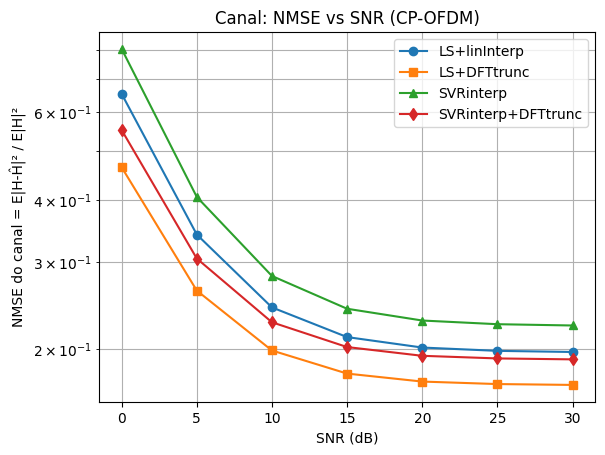

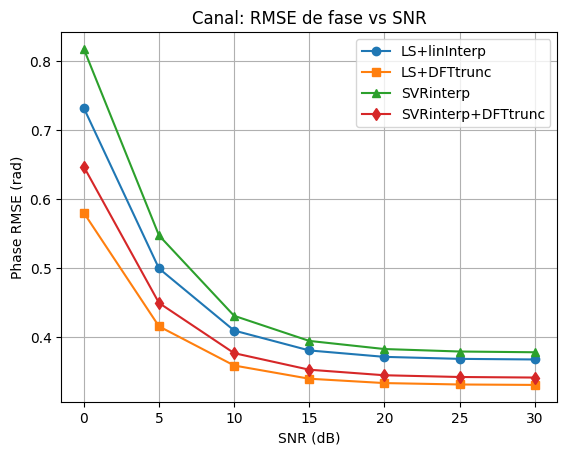

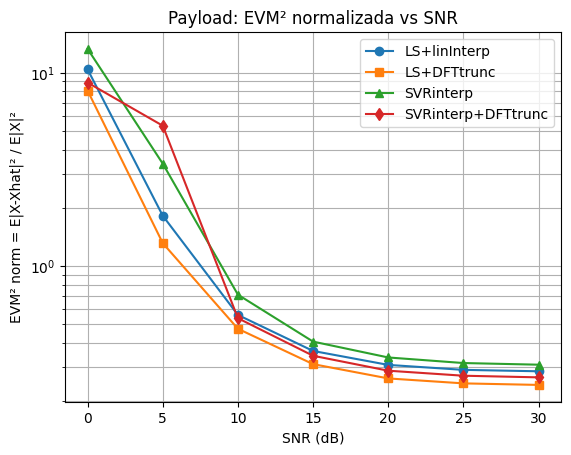

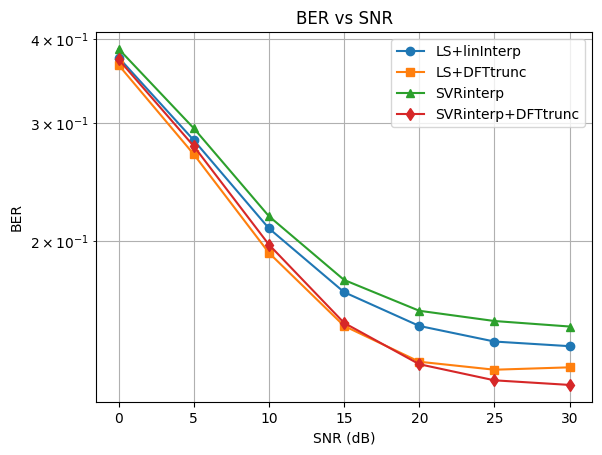

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from sklearn.svm import SVR

# ============================================================
# CONFIG (CP-OFDM coerente com o modelo clássico)
# ============================================================
K = 16                 # subportadoras
#L = 3                  # número de taps do canal (comprimento no tempo)

powers_db = np.array([0, -2.2, -4, -6, -8.2, -9.9, -10.5, -7.5])
powers_linear = 10**(powers_db/10)
powers_linear /= np.sum(powers_linear)

L = len(powers_linear)

channelResponse = (
    np.random.randn(L) + 1j*np.random.randn(L)
) * np.sqrt(powers_linear/2)

CP = L - 1             # CP >= L-1  ✅ (evita ISI intrassímbolo e preserva circularidade)
P0 = 4                 # densidade de pilotos (comb)
pilotValue = 3 + 3j
SB = 10                # símbolos OFDM por frame (dados)
mu = 4                 # bits por símbolo (16-QAM)
amostras = 2000

DD = list(range(35))
D = DD[::5]  # 0,5,10,15,20,25,30 dB

np.random.seed(42)

# ============================================================
# CARRIERS / PILOTOS (comb-type)
# ============================================================
allCarriers = np.arange(K)
pilotCarriers = allCarriers[:: K // P0]              # 0,4,8,12
pilotCarriers = np.hstack([pilotCarriers, allCarriers[-1]])  # +15 (opcional)
pilotCarriers = np.unique(pilotCarriers)
P = len(pilotCarriers)
dataCarriers = np.delete(allCarriers, pilotCarriers)
payloadBits_per_OFDM = len(dataCarriers) * mu

# ============================================================
# 16-QAM mapping/demapping (sem normalização, igual ao seu)
# ============================================================
mapping_table = {
    (0,0,0,0) : -3-3j, (0,0,0,1) : -3-1j, (0,0,1,0) : -3+3j, (0,0,1,1) : -3+1j,
    (0,1,0,0) : -1-3j, (0,1,0,1) : -1-1j, (0,1,1,0) : -1+3j, (0,1,1,1) : -1+1j,
    (1,0,0,0) :  3-3j, (1,0,0,1) :  3-1j, (1,0,1,0) :  3+3j, (1,0,1,1) :  3+1j,
    (1,1,0,0) :  1-3j, (1,1,0,1) :  1-1j, (1,1,1,0) :  1+3j, (1,1,1,1) :  1+1j
}
demapping_table = {v: k for k, v in mapping_table.items()}
constellation = np.array(list(demapping_table.keys()), dtype=np.complex128)

def SP(bits):
    return bits.reshape((len(dataCarriers), mu))

def PS(bits2d):
    return bits2d.reshape((-1,))

def Mapping(bits_sp):
    return np.array([mapping_table[tuple(b)] for b in bits_sp], dtype=np.complex128)

def Demapping(QAM):
    dists = np.abs(QAM.reshape((-1,1)) - constellation.reshape((1,-1)))
    idx = dists.argmin(axis=1)
    hardDecision = constellation[idx]
    bits_hat = np.vstack([demapping_table[c] for c in hardDecision])
    return bits_hat, hardDecision

# ============================================================
# OFDM helpers (CP-OFDM)
# ============================================================
def DFT(x):  return np.fft.fft(x)
def IDFT(X): return np.fft.ifft(X)

def add_cp(x):
    return np.concatenate([x[-CP:], x]) if CP > 0 else x

def rm_cp(y):
    return y[CP:CP+K] if CP > 0 else y[:K]

def OFDM_symbol(QAM_payload):
    X = np.zeros(K, dtype=np.complex128)
    X[pilotCarriers] = pilotValue
    X[dataCarriers] = QAM_payload
    return X

def OFDM_preamble_fullpilots():
    # preâmbulo block-type: todas subportadoras com piloto
    Xp = np.ones(K, dtype=np.complex128) * pilotValue
    return Xp

def reshape_rx_symbols(rx_data):
    # rx_data: concatenado no tempo (com CP) de SB símbolos
    sym_len = K + CP
    y_mat = rx_data.reshape((SB, sym_len))
    return y_mat

# ============================================================
# CHANNEL (L taps, AWGN)
# ============================================================
# Você pode trocar por um canal aleatório por realização se quiser; aqui mantive um fixo (como o seu)
#channelResponse = np.array([1, 0, 0.3 + 0.3j], dtype=np.complex128)
H_exact = np.fft.fft(np.r_[channelResponse, np.zeros(K - L)], K)

def channel(tx, SNRdb):
    convolved = np.convolve(tx, channelResponse)  # linear
    sigpow = np.mean(np.abs(convolved)**2)
    sigma2 = sigpow * 10**(-SNRdb/10)
    w = np.sqrt(sigma2/2) * (np.random.randn(*convolved.shape) + 1j*np.random.randn(*convolved.shape))
    return convolved + w, sigma2

# ============================================================
# Estimadores clássicos (LS em pilotos + interpolação complexa)
# ============================================================
def ls_on_pilots(Y, X):
    # LS elemento a elemento somente nos pilotos do símbolo (comb-type)
    Yp = Y[pilotCarriers]
    Xp = X[pilotCarriers]
    return Yp / (Xp + 1e-12)

def interp_complex_from_pilots(Hp):
    # Interpola real/imag separadamente para obter H em todas subportadoras (mais robusto que |.| e fase)
    fre = scipy.interpolate.interp1d(pilotCarriers, Hp.real, kind="linear", fill_value="extrapolate")(allCarriers)
    fim = scipy.interpolate.interp1d(pilotCarriers, Hp.imag, kind="linear", fill_value="extrapolate")(allCarriers)
    return fre + 1j*fim

def dft_trunc_denoise(Hhat_full, L_keep):
    # DFT-based: ifft -> zera taps >= L_keep -> fft
    hhat = np.fft.ifft(Hhat_full)
    hhat[L_keep:] = 0
    return np.fft.fft(hhat)

# ============================================================
# SVR como interpolador de H (modelo "padrão ML leve")
# ============================================================
# Features: índice normalizado da subportadora (padrão e simples)
x_pil = (pilotCarriers / (K - 1)).reshape(-1, 1)
x_all = (allCarriers  / (K - 1)).reshape(-1, 1)

def svr_interp_from_pilots(Hp, C=50.0, gamma="scale", eps=1e-3):
    # Treina 2 SVRs (real/imag) em pilotos e prevê em todas subportadoras
    svr_re = SVR(kernel="rbf", C=C, gamma=gamma, epsilon=eps)
    svr_im = SVR(kernel="rbf", C=C, gamma=gamma, epsilon=eps)
    svr_re.fit(x_pil, Hp.real)
    svr_im.fit(x_pil, Hp.imag)
    return svr_re.predict(x_all) + 1j*svr_im.predict(x_all)

# ============================================================
# Métricas
# ============================================================
def nmse(H_true, H_est, eps=1e-12):
    return np.mean(np.abs(H_true - H_est)**2) / (np.mean(np.abs(H_true)**2) + eps)

def evm2_norm(X_true, X_hat, eps=1e-12):
    return np.mean(np.abs(X_true - X_hat)**2) / (np.mean(np.abs(X_true)**2) + eps)

def phase_rmse(H_true, H_est, eps=1e-12):
    mask = np.abs(H_true) > eps
    dphi = np.angle(H_true[mask] * np.conj(H_est[mask]))
    return np.sqrt(np.mean(dphi**2))

# ============================================================
# Métodos a comparar (todos padrão / defensáveis)
# ============================================================
methods = [
    "LS+linInterp",
    "LS+DFTtrunc",
    "SVRinterp",
    "SVRinterp+DFTtrunc",
]

nmse_ch = {m: [] for m in methods}
evm2n   = {m: [] for m in methods}
ber     = {m: [] for m in methods}
phi     = {m: [] for m in methods}

# ============================================================
# MAIN SIM
# ============================================================
for SNRdb in D:
    acc = {m: {"nmse": [], "evm2n": [], "ber": [], "phi": []} for m in methods}

    for _ in range(amostras):
        # --------------------------
        # TX: preâmbulo block-type (todas subportadoras piloto)
        # --------------------------
        Xp = OFDM_preamble_fullpilots()
        xp = IDFT(Xp)
        xp_cp = add_cp(xp)

        # --------------------------
        # TX: SB símbolos com comb-pilots + dados
        # --------------------------
        bits_tx_all = []
        qam_true_all = []
        tx_syms = []

        for _sb in range(SB):
            bits = np.random.binomial(1, 0.5, size=(payloadBits_per_OFDM,))
            bits_tx_all.append(bits)
            qam = Mapping(SP(bits))
            qam_true_all.append(qam)

            X = OFDM_symbol(qam)
            x = IDFT(X)
            tx_syms.append(add_cp(x))

        bits_tx_all = np.concatenate(bits_tx_all)
        qam_true_all = np.concatenate(qam_true_all)
        tx_data = np.concatenate(tx_syms)

        tx_frame = np.concatenate([xp_cp, tx_data])
        rx_frame, _ = channel(tx_frame, SNRdb)

        # --------------------------
        # RX: extrair preâmbulo e estimar H (baseline “âncora”)
        # --------------------------
        y_preamble = rm_cp(rx_frame[:(K+CP)])
        Yp = DFT(y_preamble)

        # "H_ls_full" a partir de preâmbulo completo (melhor caso para referência)
        H_ls_full = Yp / (Xp + 1e-12)

        # --------------------------
        # RX: dados (SB símbolos)
        # --------------------------
        rx_data = rx_frame[(K+CP): (K+CP) + SB*(K+CP)]
        y_mat = reshape_rx_symbols(rx_data)  # (SB, K+CP)

        # Para manter o experimento "padrão-comb", vamos estimar H por símbolo usando pilotos comb
        # (isso é o cenário típico de interpolação; diferente do preâmbulo block-type)
        # Obs: seu canal é estático, então poderia reutilizar, mas aqui deixo geral.

        for sb_i in range(SB):
            y_sym = rm_cp(y_mat[sb_i])
            Y = DFT(y_sym)

            # Pilotos transmitidos neste símbolo
            X_sym = np.zeros(K, dtype=np.complex128)
            X_sym[pilotCarriers] = pilotValue
            X_sym[dataCarriers] = 0

            Hp_ls = ls_on_pilots(Y, X_sym)  # H nos pilotos

            # Métodos de H (por símbolo)
            H1 = interp_complex_from_pilots(Hp_ls)                    # LS+linInterp
            H2 = dft_trunc_denoise(H1, L_keep=L)                      # LS+DFTtrunc
            H3 = svr_interp_from_pilots(Hp_ls, C=50.0, gamma="scale") # SVRinterp
            H4 = dft_trunc_denoise(H3, L_keep=L)                      # SVRinterp+DFTtrunc

            H_by_method = {
                "LS+linInterp": H1,
                "LS+DFTtrunc": H2,
                "SVRinterp": H3,
                "SVRinterp+DFTtrunc": H4,
            }

            # Equalizar + demap apenas para esse símbolo
            # (para métricas por frame, vamos acumular ao longo de SB)
            # Guardamos também para NMSE/phi usando H_exact (canal fixo aqui).
            # Em canal variante: você deveria computar H_exact por símbolo.
            # --------------------------------------------------------
            # Símbolo verdadeiro (para EVM/BER)
            # --------------------------------------------------------
            # Reconstruir qam_true do símbolo atual a partir do buffer
            qam_true = qam_true_all[sb_i*len(dataCarriers):(sb_i+1)*len(dataCarriers)]
            bits_true = bits_tx_all[sb_i*payloadBits_per_OFDM:(sb_i+1)*payloadBits_per_OFDM]

            for m in methods:
                Hest = H_by_method[m]

                Yeq = Y / (Hest + 1e-12)
                qam_hat = Yeq[dataCarriers]

                b2d, _ = Demapping(qam_hat)
                bits_hat = PS(b2d)

                acc[m]["nmse"].append(nmse(H_exact, Hest))
                acc[m]["phi"].append(phase_rmse(H_exact, Hest))
                acc[m]["evm2n"].append(evm2_norm(qam_true, qam_hat))
                acc[m]["ber"].append(np.mean(bits_true != bits_hat))

    # Agregar por SNR
    for m in methods:
        nmse_ch[m].append(np.mean(acc[m]["nmse"]))
        phi[m].append(np.mean(acc[m]["phi"]))
        evm2n[m].append(np.mean(acc[m]["evm2n"]))
        ber[m].append(np.mean(acc[m]["ber"]))

    print(
        f"SNR={SNRdb:>2} dB | "
        f"NMSE: LS={nmse_ch['LS+linInterp'][-1]:.2e}  "
        f"LS+DFT={nmse_ch['LS+DFTtrunc'][-1]:.2e}  "
        f"SVR={nmse_ch['SVRinterp'][-1]:.2e}  "
        f"SVR+DFT={nmse_ch['SVRinterp+DFTtrunc'][-1]:.2e} | "
        f"EVMn: LS={evm2n['LS+linInterp'][-1]:.2e}  "
        f"SVR+DFT={evm2n['SVRinterp+DFTtrunc'][-1]:.2e} | "
        f"BER: LS={ber['LS+linInterp'][-1]:.2e}  "
        f"SVR+DFT={ber['SVRinterp+DFTtrunc'][-1]:.2e}"
    )

# ============================================================
# PLOTS
# ============================================================
def plot_semilogy_dict(y_dict, ylabel, title):
    plt.figure()
    for m, mk in zip(methods, ["o", "s", "^", "d"]):
        plt.semilogy(D, y_dict[m], marker=mk)
    plt.grid(True, which="both")
    plt.xlabel("SNR (dB)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(methods)
    plt.show()

def plot_plot_dict(y_dict, ylabel, title):
    plt.figure()
    for m, mk in zip(methods, ["o", "s", "^", "d"]):
        plt.plot(D, y_dict[m], marker=mk)
    plt.grid(True)
    plt.xlabel("SNR (dB)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(methods)
    plt.show()

plot_semilogy_dict(nmse_ch, "NMSE do canal = E|H-Ĥ|² / E|H|²", "Canal: NMSE vs SNR (CP-OFDM)")
plot_plot_dict(phi, "Phase RMSE (rad)", "Canal: RMSE de fase vs SNR")
plot_semilogy_dict(evm2n, "EVM² norm = E|X-Xhat|² / E|X|²", "Payload: EVM² normalizada vs SNR")
plot_semilogy_dict(ber, "BER", "BER vs SNR")